# [5.7] Mamba-2 and Structured State-Space Duality

## Core Question

How can one causal sequence transform be exactly the same computation when written as a recurrence, a full attention-like matrix, or a chunked SSD factorization - and when does that recurrent state matter for behavior?

**By the end of this notebook, you will have shown that the same semiseparable operator agrees across recurrent, quadratic, and chunked forms to floating-point precision, then trained a tiny Mamba-2 mixer whose recurrent state solves delayed recall while local-convolution, shuffled-label, and state-ablation controls remain near chance.**

The figure below is generated by the exercises in this notebook. It is not loaded from a verification report.

## Section Metadata

| Field | Value |
| --- | --- |
| `EXERCISE_ID` | `5_7_mamba2_ssd` |
| `GT_TIER` | `GT-1` |
| `DIFFICULTY` | `5` |
| `IMPORTANCE` | `5` |
| `EXPECTED_RUNTIME` | `about 3 minutes CPU for the complete solution path` |
| `REQUIRES_GPU` | `True` for fused-kernel and pinned-checkpoint release evidence; the complete learner path runs on CPU. |

## Learning Objectives

You will:

- derive stable segment sums and the causal semiseparable matrix;
- implement the same SSD transform recurrently and quadratically;
- factor the matrix into intra-chunk blocks and recurrent boundary states;
- implement multi-head grouped `B` and `C` parameters;
- build a gated residual Mamba-2 block with causal depthwise convolution;
- implement one-token decoding with convolution and SSM caches;
- train a small Mamba-2 mixer on delayed recall and falsify local shortcuts;
- measure runtime and the dominant materialized decay working sets;
- compare to the official SSD Listing 1 implementation and connect the operator to a pinned 130M checkpoint.

## Roadmap

This follows ARENA's from-scratch pattern: derive one tensor contract, implement it, test it immediately, then make it a component of the next object. The ground truth is the literal recurrence. The quadratic and chunked forms receive no privileged access to its outputs.

In [1]:
from __future__ import annotations

import json
import math
import os
import sys
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Iterable

os.environ["TRITON_F32_DEFAULT"] = "ieee"

import matplotlib.pyplot as plt
import torch as t
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display

chapter = "chapter5_modern_architectures"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part7_mamba2_ssd.tests as tests

EXERCISE_ID = "5_7_mamba2_ssd"
GT_TIER = "GT-1"
DIFFICULTY = 5
IMPORTANCE = 5
EXPECTED_RUNTIME = "about 3 minutes CPU for the complete solution path"
REQUIRES_GPU = True
REAL_MAMBA2_MODEL_ID = "state-spaces/mamba2-130m"
REAL_MAMBA2_REVISION = "3a5aea0c25d0fb43cc360e2c2aac82c26e3eed49"

t.set_num_threads(min(8, t.get_num_threads()))
t.set_grad_enabled(True)
t.set_float32_matmul_precision("highest")
print(f"PyTorch {t.__version__}; learner path = CPU")

PyTorch 2.12.1+cu132; learner path = CPU


## Cold open - one write, three views

Let a scalar state obey

$$h_t = a_t h_{t-1} + B_t x_t, \qquad y_t = C_t h_t.$$

Suppose `x = [2, 3, 5]`, `a = [0.9, 0.5, 0.25]`, and `B = C = 1`. The states are `[2, 4, 6]`. In matrix form, the same output is

$$
\begin{bmatrix}
1 & 0 & 0 \\
0.5 & 1 & 0 \\
0.125 & 0.25 & 1
\end{bmatrix}
\begin{bmatrix}2\\3\\5\end{bmatrix}.
$$

The key indexing fact is easy to get wrong: a write at source `s` is multiplied by transitions `s+1` through `t`, not by `a_s`. You will make that rule executable first.

### Exercise 1 - stable segment sums

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 15 minutes
> ```

Implement `S[t,s] = sum(log_decay[s+1:t+1])`. Use `-inf` above the diagonal so exponentiation enforces causality. Do not compute this as a difference of cumulative sums.

<details><summary>Expected output</summary>

```text
All tests in `test_segment_sums_exact` passed!
```

</details>

<details><summary>Help - common bug</summary>

Repeat each transition down a matrix, zero everything outside the strict lower triangle, and cumulative-sum down the destination axis. The diagonal must stay zero.

</details>

<details><summary>Solution</summary>

```python
def segment_sums(log_decay: t.Tensor) -> t.Tensor:
    """Return S[t, s] = sum(log_decay[s + 1 : t + 1]) for t >= s.

    Unlike a difference of cumulative sums, this construction does not
    subtract nearby large numbers. Entries above the diagonal are -inf so
    exponentiation produces a causal lower-triangular decay matrix.
    """

    if log_decay.ndim < 1:
        raise ValueError("log_decay must have a sequence axis")
    length = log_decay.shape[-1]
    repeated = log_decay.unsqueeze(-1).expand(*log_decay.shape, length)
    strict_lower = t.tril(
        t.ones(length, length, dtype=t.bool, device=log_decay.device),
        diagonal=-1,
    )
    contributions = repeated.masked_fill(~strict_lower, 0)
    sums = contributions.cumsum(dim=-2)
    causal = t.tril(
        t.ones(length, length, dtype=t.bool, device=log_decay.device)
    )
    return sums.masked_fill(~causal, -t.inf)

tests.test_segment_sums_exact(segment_sums)
```

</details>

In [2]:
def segment_sums(log_decay: t.Tensor) -> t.Tensor:
    """Return S[t, s] = sum(log_decay[s + 1 : t + 1]) for t >= s.

    Unlike a difference of cumulative sums, this construction does not
    subtract nearby large numbers. Entries above the diagonal are -inf so
    exponentiation produces a causal lower-triangular decay matrix.
    """

    if log_decay.ndim < 1:
        raise ValueError("log_decay must have a sequence axis")
    length = log_decay.shape[-1]
    repeated = log_decay.unsqueeze(-1).expand(*log_decay.shape, length)
    strict_lower = t.tril(
        t.ones(length, length, dtype=t.bool, device=log_decay.device),
        diagonal=-1,
    )
    contributions = repeated.masked_fill(~strict_lower, 0)
    sums = contributions.cumsum(dim=-2)
    causal = t.tril(
        t.ones(length, length, dtype=t.bool, device=log_decay.device)
    )
    return sums.masked_fill(~causal, -t.inf)

tests.test_segment_sums_exact(segment_sums)

All tests in `test_segment_sums_exact` passed!


### Exercise 2 - the semiseparable attention-dual matrix

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 20 minutes
> ```

Expand grouped `B/C` parameters over heads, then materialize `M[t,s] = C_t^T B_s exp(S[t,s])`. This is attention-like - `C` behaves like queries, `B` like keys, and `X` like values - but its causal mask is a structured product of scalar transitions.

<details><summary>Expected output</summary>

```text
All tests in `test_expand_grouped_parameters` passed!
All tests in `test_semiseparable_matrix_hand_oracle` passed!
```

</details>

<details><summary>Help - common bug</summary>

For four heads and two groups, the map is `[0,0,1,1]`, not `[0,1,0,1]`. Contract state dimension `N` only after expanding groups.

</details>

<details><summary>Solution</summary>

```python
def expand_grouped_parameters(
    B: t.Tensor,
    C: t.Tensor,
    n_heads: int,
) -> tuple[t.Tensor, t.Tensor]:
    """Repeat each parameter group across its contiguous block of heads."""

    if B.shape != C.shape or B.ndim != 4:
        raise ValueError("B and C must both have shape [batch, length, groups, state]")
    n_groups = B.shape[2]
    if n_heads % n_groups != 0:
        raise ValueError("n_heads must be divisible by the number of groups")
    repeats = n_heads // n_groups
    return B.repeat_interleave(repeats, dim=2), C.repeat_interleave(repeats, dim=2)

def semiseparable_matrix(
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
) -> t.Tensor:
    """Materialize the causal SSD mixing matrix for every head.

    Shapes are log_decay [B, L, H], B/C [B, L, G, N], and output
    [B, H, L, L]. The matrix entry is C_t^T B_s times the product of
    transitions strictly after source s and through destination t.
    """

    if log_decay.ndim != 3:
        raise ValueError("log_decay must have shape [batch, length, heads]")
    B_heads, C_heads = expand_grouped_parameters(B, C, log_decay.shape[2])
    decay = segment_sums(log_decay.transpose(1, 2)).exp()
    content = t.einsum("bthn,bshn->bhts", C_heads, B_heads)
    return decay * content

tests.test_expand_grouped_parameters(expand_grouped_parameters)
tests.test_semiseparable_matrix_hand_oracle(semiseparable_matrix)
```

</details>

In [3]:
def expand_grouped_parameters(
    B: t.Tensor,
    C: t.Tensor,
    n_heads: int,
) -> tuple[t.Tensor, t.Tensor]:
    """Repeat each parameter group across its contiguous block of heads."""

    if B.shape != C.shape or B.ndim != 4:
        raise ValueError("B and C must both have shape [batch, length, groups, state]")
    n_groups = B.shape[2]
    if n_heads % n_groups != 0:
        raise ValueError("n_heads must be divisible by the number of groups")
    repeats = n_heads // n_groups
    return B.repeat_interleave(repeats, dim=2), C.repeat_interleave(repeats, dim=2)

def semiseparable_matrix(
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
) -> t.Tensor:
    """Materialize the causal SSD mixing matrix for every head.

    Shapes are log_decay [B, L, H], B/C [B, L, G, N], and output
    [B, H, L, L]. The matrix entry is C_t^T B_s times the product of
    transitions strictly after source s and through destination t.
    """

    if log_decay.ndim != 3:
        raise ValueError("log_decay must have shape [batch, length, heads]")
    B_heads, C_heads = expand_grouped_parameters(B, C, log_decay.shape[2])
    decay = segment_sums(log_decay.transpose(1, 2)).exp()
    content = t.einsum("bthn,bshn->bhts", C_heads, B_heads)
    return decay * content

tests.test_expand_grouped_parameters(expand_grouped_parameters)
tests.test_semiseparable_matrix_hand_oracle(semiseparable_matrix)

All tests in `test_expand_grouped_parameters` passed!
All tests in `test_semiseparable_matrix_hand_oracle` passed!


### Exercise 3 - the recurrent ground-truth SSD

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 20 minutes
> ```

Implement the recurrence literally with state shape `[batch, heads, head_dim, state_dim]`. Return every output and the final state. Add a `carry_scale` intervention so `0` removes only information from earlier tokens.

<details><summary>Expected output</summary>

```text
All tests in `test_recurrent_ssd_hand_oracle` passed!
```

</details>

<details><summary>Help - common bug</summary>

At each token: decay the previous state, add the outer product `X_t B_t`, then contract with `C_t`. Read after write. The state-ablation control must still retain the current write.

</details>

<details><summary>Solution</summary>

```python
def ssd_recurrent(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
    initial_state: t.Tensor | None = None,
    *,
    carry_scale: float = 1.0,
) -> tuple[t.Tensor, t.Tensor]:
    """Evaluate SSD as the literal recurrent state update.

    X has shape [B, L, H, P]. The state has shape [B, H, P, N]. Setting
    carry_scale to zero is a causal state-ablation control, not a different
    task: each token can still write and read its current contribution.
    """

    if X.ndim != 4 or log_decay.shape != X.shape[:3]:
        raise ValueError("X must be [batch, length, heads, head_dim]")
    B_heads, C_heads = expand_grouped_parameters(B, C, X.shape[2])
    expected_state = (X.shape[0], X.shape[2], X.shape[3], B.shape[-1])
    state = (
        X.new_zeros(expected_state)
        if initial_state is None
        else initial_state.to(device=X.device, dtype=X.dtype)
    )
    if state.shape != expected_state:
        raise ValueError(f"initial_state must have shape {expected_state}")
    outputs = []
    for position in range(X.shape[1]):
        transition = log_decay[:, position].exp()[..., None, None]
        write = t.einsum(
            "bhp,bhn->bhpn",
            X[:, position],
            B_heads[:, position],
        )
        state = float(carry_scale) * transition * state + write
        outputs.append(
            t.einsum("bhn,bhpn->bhp", C_heads[:, position], state)
        )
    return t.stack(outputs, dim=1), state

tests.test_recurrent_ssd_hand_oracle(ssd_recurrent)
```

</details>

In [4]:
def ssd_recurrent(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
    initial_state: t.Tensor | None = None,
    *,
    carry_scale: float = 1.0,
) -> tuple[t.Tensor, t.Tensor]:
    """Evaluate SSD as the literal recurrent state update.

    X has shape [B, L, H, P]. The state has shape [B, H, P, N]. Setting
    carry_scale to zero is a causal state-ablation control, not a different
    task: each token can still write and read its current contribution.
    """

    if X.ndim != 4 or log_decay.shape != X.shape[:3]:
        raise ValueError("X must be [batch, length, heads, head_dim]")
    B_heads, C_heads = expand_grouped_parameters(B, C, X.shape[2])
    expected_state = (X.shape[0], X.shape[2], X.shape[3], B.shape[-1])
    state = (
        X.new_zeros(expected_state)
        if initial_state is None
        else initial_state.to(device=X.device, dtype=X.dtype)
    )
    if state.shape != expected_state:
        raise ValueError(f"initial_state must have shape {expected_state}")
    outputs = []
    for position in range(X.shape[1]):
        transition = log_decay[:, position].exp()[..., None, None]
        write = t.einsum(
            "bhp,bhn->bhpn",
            X[:, position],
            B_heads[:, position],
        )
        state = float(carry_scale) * transition * state + write
        outputs.append(
            t.einsum("bhn,bhpn->bhp", C_heads[:, position], state)
        )
    return t.stack(outputs, dim=1), state

tests.test_recurrent_ssd_hand_oracle(ssd_recurrent)

All tests in `test_recurrent_ssd_hand_oracle` passed!


### Exercise 4 - the quadratic dual form

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 15 minutes
> ```

Use the semiseparable matrix to mix the value sequence with one contraction. Test it against the independently implemented recurrence and perturb a future token by 10,000 to test causality.

<details><summary>Expected output</summary>

```text
All tests in `test_quadratic_ssd_parity_and_causality` passed!
```

</details>

<details><summary>Help - common bug</summary>

The mixing matrix is `[batch, heads, destination, source]`; `X` is `[batch, source, heads, head_dim]`. Name the einsum axes before writing it.

</details>

<details><summary>Solution</summary>

```python
def ssd_quadratic(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
) -> t.Tensor:
    """Evaluate SSD through its full semiseparable attention-dual matrix."""

    mixing = semiseparable_matrix(log_decay, B, C)
    return t.einsum("bhts,bshp->bthp", mixing, X)

tests.test_quadratic_ssd_parity_and_causality(ssd_recurrent, ssd_quadratic)
```

</details>

In [5]:
def ssd_quadratic(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
) -> t.Tensor:
    """Evaluate SSD through its full semiseparable attention-dual matrix."""

    mixing = semiseparable_matrix(log_decay, B, C)
    return t.einsum("bhts,bshp->bthp", mixing, X)

tests.test_quadratic_ssd_parity_and_causality(ssd_recurrent, ssd_quadratic)

All tests in `test_quadratic_ssd_parity_and_causality` passed!


### Exercise 5 - chunked SSD

> ```yaml
> Difficulty: 5/5
> Importance: 5/5
> Suggested time: 45 minutes
> ```

Factor the full matrix into diagonal chunk blocks plus low-rank off-diagonal blocks. Compute local outputs, compress writes to chunk-boundary states, scan only those boundaries, then expand incoming states inside each chunk.

<details><summary>Expected output</summary>

```text
All tests in `test_chunked_ssd_parity_state_and_gradients` passed!
All tests in `test_official_listing_one_parity` passed!
```

</details>

<details><summary>Help - common bug</summary>

There are two different decays: source-to-end-of-chunk for compressed writes, and start-of-chunk-to-destination for incoming states. Padding tokens need zero log-decay so they preserve the final cache.

</details>

<details><summary>Solution</summary>

```python
def ssd_chunked(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
    chunk_size: int,
    initial_state: t.Tensor | None = None,
) -> tuple[t.Tensor, t.Tensor]:
    """Evaluate SSD using diagonal blocks plus low-rank boundary states.

    The only recurrent loop is over chunks. Work inside each chunk is a
    quadratic tensor contraction, exposing the semiseparable block structure
    used by the hardware-aware Mamba-2 algorithm.
    """

    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive")
    if X.ndim != 4 or log_decay.shape != X.shape[:3]:
        raise ValueError("X must be [batch, length, heads, head_dim]")
    batch, original_length, n_heads, head_dim = X.shape
    B_heads, C_heads = expand_grouped_parameters(B, C, n_heads)
    d_state = B_heads.shape[-1]

    pad = (-original_length) % chunk_size
    if pad:
        X = F.pad(X, (0, 0, 0, 0, 0, pad))
        log_decay = F.pad(log_decay, (0, 0, 0, pad))
        B_heads = F.pad(B_heads, (0, 0, 0, 0, 0, pad))
        C_heads = F.pad(C_heads, (0, 0, 0, 0, 0, pad))

    length = X.shape[1]
    n_chunks = length // chunk_size
    Xc = X.reshape(batch, n_chunks, chunk_size, n_heads, head_dim)
    Bc = B_heads.reshape(batch, n_chunks, chunk_size, n_heads, d_state)
    Cc = C_heads.reshape(batch, n_chunks, chunk_size, n_heads, d_state)
    Ac = log_decay.reshape(batch, n_chunks, chunk_size, n_heads).permute(0, 3, 1, 2)
    A_prefix = Ac.cumsum(dim=-1)

    # Diagonal blocks: interactions whose source and destination share a chunk.
    intra_decay = segment_sums(Ac).exp()
    Y_diag = t.einsum(
        "bcqhn,bckhn,bhcqk,bckhp->bcqhp",
        Cc,
        Bc,
        intra_decay,
        Xc,
    )

    # Each chunk compresses all of its writes into one outgoing boundary state.
    decay_to_end = (A_prefix[..., -1:] - A_prefix).exp()
    chunk_writes = t.einsum(
        "bckhn,bhck,bckhp->bchpn",
        Bc,
        decay_to_end,
        Xc,
    )

    expected_state = (batch, n_heads, head_dim, d_state)
    state = (
        X.new_zeros(expected_state)
        if initial_state is None
        else initial_state.to(device=X.device, dtype=X.dtype)
    )
    if state.shape != expected_state:
        raise ValueError(f"initial_state must have shape {expected_state}")
    incoming_states = []
    for chunk in range(n_chunks):
        incoming_states.append(state)
        chunk_transition = A_prefix[:, :, chunk, -1].exp()[..., None, None]
        state = chunk_transition * state + chunk_writes[:, chunk]
    incoming = t.stack(incoming_states, dim=1)

    # Off-diagonal blocks: expand each incoming boundary state through its chunk.
    state_decay_out = A_prefix.exp()
    Y_off = t.einsum(
        "bcqhn,bchpn,bhcq->bcqhp",
        Cc,
        incoming,
        state_decay_out,
    )
    output = (Y_diag + Y_off).reshape(batch, length, n_heads, head_dim)
    return output[:, :original_length], state

tests.test_chunked_ssd_parity_state_and_gradients(ssd_recurrent, ssd_chunked)
```

</details>

In [6]:
def ssd_chunked(
    X: t.Tensor,
    log_decay: t.Tensor,
    B: t.Tensor,
    C: t.Tensor,
    chunk_size: int,
    initial_state: t.Tensor | None = None,
) -> tuple[t.Tensor, t.Tensor]:
    """Evaluate SSD using diagonal blocks plus low-rank boundary states.

    The only recurrent loop is over chunks. Work inside each chunk is a
    quadratic tensor contraction, exposing the semiseparable block structure
    used by the hardware-aware Mamba-2 algorithm.
    """

    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive")
    if X.ndim != 4 or log_decay.shape != X.shape[:3]:
        raise ValueError("X must be [batch, length, heads, head_dim]")
    batch, original_length, n_heads, head_dim = X.shape
    B_heads, C_heads = expand_grouped_parameters(B, C, n_heads)
    d_state = B_heads.shape[-1]

    pad = (-original_length) % chunk_size
    if pad:
        X = F.pad(X, (0, 0, 0, 0, 0, pad))
        log_decay = F.pad(log_decay, (0, 0, 0, pad))
        B_heads = F.pad(B_heads, (0, 0, 0, 0, 0, pad))
        C_heads = F.pad(C_heads, (0, 0, 0, 0, 0, pad))

    length = X.shape[1]
    n_chunks = length // chunk_size
    Xc = X.reshape(batch, n_chunks, chunk_size, n_heads, head_dim)
    Bc = B_heads.reshape(batch, n_chunks, chunk_size, n_heads, d_state)
    Cc = C_heads.reshape(batch, n_chunks, chunk_size, n_heads, d_state)
    Ac = log_decay.reshape(batch, n_chunks, chunk_size, n_heads).permute(0, 3, 1, 2)
    A_prefix = Ac.cumsum(dim=-1)

    # Diagonal blocks: interactions whose source and destination share a chunk.
    intra_decay = segment_sums(Ac).exp()
    Y_diag = t.einsum(
        "bcqhn,bckhn,bhcqk,bckhp->bcqhp",
        Cc,
        Bc,
        intra_decay,
        Xc,
    )

    # Each chunk compresses all of its writes into one outgoing boundary state.
    decay_to_end = (A_prefix[..., -1:] - A_prefix).exp()
    chunk_writes = t.einsum(
        "bckhn,bhck,bckhp->bchpn",
        Bc,
        decay_to_end,
        Xc,
    )

    expected_state = (batch, n_heads, head_dim, d_state)
    state = (
        X.new_zeros(expected_state)
        if initial_state is None
        else initial_state.to(device=X.device, dtype=X.dtype)
    )
    if state.shape != expected_state:
        raise ValueError(f"initial_state must have shape {expected_state}")
    incoming_states = []
    for chunk in range(n_chunks):
        incoming_states.append(state)
        chunk_transition = A_prefix[:, :, chunk, -1].exp()[..., None, None]
        state = chunk_transition * state + chunk_writes[:, chunk]
    incoming = t.stack(incoming_states, dim=1)

    # Off-diagonal blocks: expand each incoming boundary state through its chunk.
    state_decay_out = A_prefix.exp()
    Y_off = t.einsum(
        "bcqhn,bchpn,bhcq->bcqhp",
        Cc,
        incoming,
        state_decay_out,
    )
    output = (Y_diag + Y_off).reshape(batch, length, n_heads, head_dim)
    return output[:, :original_length], state

tests.test_chunked_ssd_parity_state_and_gradients(ssd_recurrent, ssd_chunked)

All tests in `test_chunked_ssd_parity_state_and_gradients` passed!


<details><summary>Interpretation - what parity establishes</summary>

Agreement with the recurrence establishes mathematical correctness for the stated tensor contract. Agreement with the official repository's independent Listing 1 implementation connects our notation and indexing to the released Mamba-2 code. It does **not** establish that this unfused educational Python is fast; that is a separate kernel claim tested on CUDA.

</details>

In [7]:
def make_ssd_inputs(
    *,
    length: int = 32,
    batch: int = 2,
    n_heads: int = 4,
    n_groups: int = 2,
    head_dim: int = 3,
    d_state: int = 5,
    seed: int = 0,
    dtype: t.dtype = t.float64,
    device: t.device | str = "cpu",
) -> tuple[t.Tensor, t.Tensor, t.Tensor, t.Tensor]:
    generator = t.Generator().manual_seed(seed)
    X = t.randn(batch, length, n_heads, head_dim, generator=generator, dtype=dtype)
    log_decay = -0.02 - 0.3 * t.rand(
        batch, length, n_heads, generator=generator, dtype=dtype
    )
    B = t.randn(batch, length, n_groups, d_state, generator=generator, dtype=dtype)
    C = t.randn(batch, length, n_groups, d_state, generator=generator, dtype=dtype)
    return tuple(value.to(device) for value in (X, log_decay, B, C))

def official_ssd_reference_parity(
    *,
    length: int = 32,
    chunk_size: int = 8,
    device: t.device | str = "cpu",
) -> dict[str, float]:
    """Compare against Listing 1 in the installed official Mamba repository."""

    from mamba_ssm.modules.ssd_minimal import ssd_minimal_discrete

    X, A, B, C = make_ssd_inputs(
        length=length,
        batch=1,
        n_heads=4,
        n_groups=1,
        head_dim=3,
        d_state=5,
        device=device,
    )
    B_heads, C_heads = expand_grouped_parameters(B, C, X.shape[2])
    ours, ours_state = ssd_chunked(X, A, B_heads, C_heads, chunk_size)
    official, official_state = ssd_minimal_discrete(
        X,
        A,
        B_heads,
        C_heads,
        chunk_size,
    )
    return {
        "output_max_abs_diff": float((ours - official).abs().max()),
        "final_state_max_abs_diff": float((ours_state - official_state).abs().max()),
    }

print(official_ssd_reference_parity())
tests.test_official_listing_one_parity(official_ssd_reference_parity)

{'output_max_abs_diff': 8.881784197001252e-16, 'final_state_max_abs_diff': 4.440892098500626e-16}
All tests in `test_official_listing_one_parity` passed!


### Exercise 6 - a multi-head gated residual Mamba-2 block

> ```yaml
> Difficulty: 5/5
> Importance: 5/5
> Suggested time: 45 minutes
> ```

Compose one input projection into `z/x/B/C/dt`, a causal depthwise convolution over `x/B/C`, grouped SSD heads, a learned skip `D`, RMS normalization, SiLU gate, output projection, and residual connection.

<details><summary>Expected output</summary>

```text
All tests in `test_mamba2_block_shape_and_causality` passed!
```

</details>

<details><summary>Help - common bug</summary>

The convolution acts on `x/B/C`, not on `z` or `dt`. Reshape only `x` into heads; `B/C` retain group axes until SSD expands them. Keep continuous `A=-exp(A_log)` negative.

</details>

<details><summary>Solution</summary>

```python
def causal_depthwise_conv1d(
    X: t.Tensor,
    weight: t.Tensor,
    bias: t.Tensor | None = None,
) -> t.Tensor:
    """Causal depthwise cross-correlation for [batch, length, channels]."""

    if X.ndim != 3 or weight.ndim != 2 or weight.shape[0] != X.shape[-1]:
        raise ValueError("X must be [B,L,C] and weight must be [C,kernel]")
    channels, kernel_size = weight.shape
    padded = F.pad(X.transpose(1, 2), (kernel_size - 1, 0))
    return F.conv1d(
        padded,
        weight[:, None],
        bias=bias,
        groups=channels,
    ).transpose(1, 2)

def rms_norm_gated(
    Y: t.Tensor,
    gate: t.Tensor,
    weight: t.Tensor,
    eps: float = 1e-5,
) -> t.Tensor:
    """RMS-normalize the SSD output, then apply a SiLU gate."""

    normalized = Y * t.rsqrt(Y.square().mean(dim=-1, keepdim=True) + eps)
    return normalized * weight * F.silu(gate)

@dataclass(frozen=True)
class Mamba2Config:
    d_model: int = 12
    d_state: int = 4
    d_conv: int = 3
    expand: int = 1
    head_dim: int = 3
    n_groups: int = 1
    chunk_size: int = 8

    @property
    def d_inner(self) -> int:
        return self.expand * self.d_model

    @property
    def n_heads(self) -> int:
        if self.d_inner % self.head_dim:
            raise ValueError("expand*d_model must be divisible by head_dim")
        return self.d_inner // self.head_dim

@dataclass
class Mamba2Cache:
    conv_state: t.Tensor
    ssm_state: t.Tensor


class Mamba2BlockFromScratch(nn.Module):
    """A small, readable Mamba-2 residual block built around chunked SSD."""

    def __init__(self, config: Mamba2Config):
        super().__init__()
        self.config = config
        h, p, g, n = (
            config.n_heads,
            config.head_dim,
            config.n_groups,
            config.d_state,
        )
        if h % g:
            raise ValueError("n_heads must be divisible by n_groups")
        projection_size = 2 * config.d_inner + 2 * g * n + h
        self.in_proj = nn.Linear(config.d_model, projection_size, bias=False)
        conv_channels = config.d_inner + 2 * g * n
        self.conv1d = nn.Conv1d(
            conv_channels,
            conv_channels,
            config.d_conv,
            groups=conv_channels,
        )
        self.dt_bias = nn.Parameter(t.full((h,), -2.5))
        self.A_log = nn.Parameter(t.linspace(0.0, math.log(4.0), h))
        self.D = nn.Parameter(t.ones(h))
        self.norm_weight = nn.Parameter(t.ones(config.d_inner))
        self.out_proj = nn.Linear(config.d_inner, config.d_model, bias=False)

    def _project(self, U: t.Tensor) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
        c = self.config
        projected = self.in_proj(U)
        return t.split(
            projected,
            [c.d_inner, c.d_inner + 2 * c.n_groups * c.d_state, c.n_heads],
            dim=-1,
        )

    def _mix_from_convolved(
        self,
        U: t.Tensor,
        Z: t.Tensor,
        XBC: t.Tensor,
        dt_logits: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, t.Tensor]:
        c = self.config
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(*X.shape[:2], c.n_heads, c.head_dim)
        B = B.reshape(*B.shape[:2], c.n_groups, c.d_state)
        C = C.reshape(*C.shape[:2], c.n_groups, c.d_state)
        dt = F.softplus(dt_logits + self.dt_bias)
        log_decay = dt * (-self.A_log.exp())
        if carry_scale == 1.0:
            Y, final_state = ssd_chunked(
                X * dt[..., None],
                log_decay,
                B,
                C,
                c.chunk_size,
            )
        else:
            Y, final_state = ssd_recurrent(
                X * dt[..., None],
                log_decay,
                B,
                C,
                carry_scale=carry_scale,
            )
        Y = Y + self.D[None, None, :, None] * X
        Y = Y.reshape(*Y.shape[:2], c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        return U + self.out_proj(mixed), final_state

    def forward(
        self,
        U: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> t.Tensor:
        if U.ndim != 3 or U.shape[-1] != self.config.d_model:
            raise ValueError("U must have shape [batch, length, d_model]")
        Z, XBC, dt_logits = self._project(U)
        conv_weight = self.conv1d.weight[:, 0]
        XBC = F.silu(causal_depthwise_conv1d(XBC, conv_weight, self.conv1d.bias))
        output, _ = self._mix_from_convolved(
            U,
            Z,
            XBC,
            dt_logits,
            carry_scale=carry_scale,
        )
        return output

    def allocate_cache(
        self,
        batch_size: int,
        *,
        device: t.device | str,
        dtype: t.dtype,
    ) -> Mamba2Cache:
        c = self.config
        conv_channels = c.d_inner + 2 * c.n_groups * c.d_state
        return Mamba2Cache(
            conv_state=t.zeros(
                batch_size,
                conv_channels,
                c.d_conv,
                device=device,
                dtype=dtype,
            ),
            ssm_state=t.zeros(
                batch_size,
                c.n_heads,
                c.head_dim,
                c.d_state,
                device=device,
                dtype=dtype,
            ),
        )

    def step(
        self,
        U: t.Tensor,
        cache: Mamba2Cache,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, Mamba2Cache]:
        """Decode one token while updating convolution and SSM caches."""

        if U.ndim == 2:
            U = U[:, None]
        if U.ndim != 3 or U.shape[1] != 1:
            raise ValueError("step expects [batch, d_model] or [batch, 1, d_model]")
        c = self.config
        Z, XBC_raw, dt_logits = self._project(U)
        conv_state = t.cat(
            [cache.conv_state[..., 1:], XBC_raw[:, 0, :, None]],
            dim=-1,
        )
        conv_value = (
            conv_state * self.conv1d.weight[:, 0][None]
        ).sum(dim=-1) + self.conv1d.bias
        XBC = F.silu(conv_value[:, None])
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(U.shape[0], c.n_heads, c.head_dim)
        B = B.reshape(U.shape[0], c.n_groups, c.d_state)
        C = C.reshape(U.shape[0], c.n_groups, c.d_state)
        B_heads, C_heads = expand_grouped_parameters(B[:, None], C[:, None], c.n_heads)
        B_heads, C_heads = B_heads[:, 0], C_heads[:, 0]
        dt = F.softplus(dt_logits[:, 0] + self.dt_bias)
        transition = (dt * (-self.A_log.exp())).exp()[..., None, None]
        write = t.einsum("bhp,bhn->bhpn", X * dt[..., None], B_heads)
        ssm_state = float(carry_scale) * transition * cache.ssm_state + write
        Y = t.einsum("bhn,bhpn->bhp", C_heads, ssm_state)
        Y = Y + self.D[None, :, None] * X
        Y = Y.reshape(U.shape[0], 1, c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        output = U + self.out_proj(mixed)
        return output, Mamba2Cache(conv_state=conv_state, ssm_state=ssm_state)

tests.test_mamba2_block_shape_and_causality(Mamba2BlockFromScratch, Mamba2Config)
```

</details>

In [8]:
def causal_depthwise_conv1d(
    X: t.Tensor,
    weight: t.Tensor,
    bias: t.Tensor | None = None,
) -> t.Tensor:
    """Causal depthwise cross-correlation for [batch, length, channels]."""

    if X.ndim != 3 or weight.ndim != 2 or weight.shape[0] != X.shape[-1]:
        raise ValueError("X must be [B,L,C] and weight must be [C,kernel]")
    channels, kernel_size = weight.shape
    padded = F.pad(X.transpose(1, 2), (kernel_size - 1, 0))
    return F.conv1d(
        padded,
        weight[:, None],
        bias=bias,
        groups=channels,
    ).transpose(1, 2)

def rms_norm_gated(
    Y: t.Tensor,
    gate: t.Tensor,
    weight: t.Tensor,
    eps: float = 1e-5,
) -> t.Tensor:
    """RMS-normalize the SSD output, then apply a SiLU gate."""

    normalized = Y * t.rsqrt(Y.square().mean(dim=-1, keepdim=True) + eps)
    return normalized * weight * F.silu(gate)

@dataclass(frozen=True)
class Mamba2Config:
    d_model: int = 12
    d_state: int = 4
    d_conv: int = 3
    expand: int = 1
    head_dim: int = 3
    n_groups: int = 1
    chunk_size: int = 8

    @property
    def d_inner(self) -> int:
        return self.expand * self.d_model

    @property
    def n_heads(self) -> int:
        if self.d_inner % self.head_dim:
            raise ValueError("expand*d_model must be divisible by head_dim")
        return self.d_inner // self.head_dim

@dataclass
class Mamba2Cache:
    conv_state: t.Tensor
    ssm_state: t.Tensor


class Mamba2BlockFromScratch(nn.Module):
    """A small, readable Mamba-2 residual block built around chunked SSD."""

    def __init__(self, config: Mamba2Config):
        super().__init__()
        self.config = config
        h, p, g, n = (
            config.n_heads,
            config.head_dim,
            config.n_groups,
            config.d_state,
        )
        if h % g:
            raise ValueError("n_heads must be divisible by n_groups")
        projection_size = 2 * config.d_inner + 2 * g * n + h
        self.in_proj = nn.Linear(config.d_model, projection_size, bias=False)
        conv_channels = config.d_inner + 2 * g * n
        self.conv1d = nn.Conv1d(
            conv_channels,
            conv_channels,
            config.d_conv,
            groups=conv_channels,
        )
        self.dt_bias = nn.Parameter(t.full((h,), -2.5))
        self.A_log = nn.Parameter(t.linspace(0.0, math.log(4.0), h))
        self.D = nn.Parameter(t.ones(h))
        self.norm_weight = nn.Parameter(t.ones(config.d_inner))
        self.out_proj = nn.Linear(config.d_inner, config.d_model, bias=False)

    def _project(self, U: t.Tensor) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
        c = self.config
        projected = self.in_proj(U)
        return t.split(
            projected,
            [c.d_inner, c.d_inner + 2 * c.n_groups * c.d_state, c.n_heads],
            dim=-1,
        )

    def _mix_from_convolved(
        self,
        U: t.Tensor,
        Z: t.Tensor,
        XBC: t.Tensor,
        dt_logits: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, t.Tensor]:
        c = self.config
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(*X.shape[:2], c.n_heads, c.head_dim)
        B = B.reshape(*B.shape[:2], c.n_groups, c.d_state)
        C = C.reshape(*C.shape[:2], c.n_groups, c.d_state)
        dt = F.softplus(dt_logits + self.dt_bias)
        log_decay = dt * (-self.A_log.exp())
        if carry_scale == 1.0:
            Y, final_state = ssd_chunked(
                X * dt[..., None],
                log_decay,
                B,
                C,
                c.chunk_size,
            )
        else:
            Y, final_state = ssd_recurrent(
                X * dt[..., None],
                log_decay,
                B,
                C,
                carry_scale=carry_scale,
            )
        Y = Y + self.D[None, None, :, None] * X
        Y = Y.reshape(*Y.shape[:2], c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        return U + self.out_proj(mixed), final_state

    def forward(
        self,
        U: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> t.Tensor:
        if U.ndim != 3 or U.shape[-1] != self.config.d_model:
            raise ValueError("U must have shape [batch, length, d_model]")
        Z, XBC, dt_logits = self._project(U)
        conv_weight = self.conv1d.weight[:, 0]
        XBC = F.silu(causal_depthwise_conv1d(XBC, conv_weight, self.conv1d.bias))
        output, _ = self._mix_from_convolved(
            U,
            Z,
            XBC,
            dt_logits,
            carry_scale=carry_scale,
        )
        return output

    def allocate_cache(
        self,
        batch_size: int,
        *,
        device: t.device | str,
        dtype: t.dtype,
    ) -> Mamba2Cache:
        c = self.config
        conv_channels = c.d_inner + 2 * c.n_groups * c.d_state
        return Mamba2Cache(
            conv_state=t.zeros(
                batch_size,
                conv_channels,
                c.d_conv,
                device=device,
                dtype=dtype,
            ),
            ssm_state=t.zeros(
                batch_size,
                c.n_heads,
                c.head_dim,
                c.d_state,
                device=device,
                dtype=dtype,
            ),
        )

    def step(
        self,
        U: t.Tensor,
        cache: Mamba2Cache,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, Mamba2Cache]:
        """Decode one token while updating convolution and SSM caches."""

        if U.ndim == 2:
            U = U[:, None]
        if U.ndim != 3 or U.shape[1] != 1:
            raise ValueError("step expects [batch, d_model] or [batch, 1, d_model]")
        c = self.config
        Z, XBC_raw, dt_logits = self._project(U)
        conv_state = t.cat(
            [cache.conv_state[..., 1:], XBC_raw[:, 0, :, None]],
            dim=-1,
        )
        conv_value = (
            conv_state * self.conv1d.weight[:, 0][None]
        ).sum(dim=-1) + self.conv1d.bias
        XBC = F.silu(conv_value[:, None])
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(U.shape[0], c.n_heads, c.head_dim)
        B = B.reshape(U.shape[0], c.n_groups, c.d_state)
        C = C.reshape(U.shape[0], c.n_groups, c.d_state)
        B_heads, C_heads = expand_grouped_parameters(B[:, None], C[:, None], c.n_heads)
        B_heads, C_heads = B_heads[:, 0], C_heads[:, 0]
        dt = F.softplus(dt_logits[:, 0] + self.dt_bias)
        transition = (dt * (-self.A_log.exp())).exp()[..., None, None]
        write = t.einsum("bhp,bhn->bhpn", X * dt[..., None], B_heads)
        ssm_state = float(carry_scale) * transition * cache.ssm_state + write
        Y = t.einsum("bhn,bhpn->bhp", C_heads, ssm_state)
        Y = Y + self.D[None, :, None] * X
        Y = Y.reshape(U.shape[0], 1, c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        output = U + self.out_proj(mixed)
        return output, Mamba2Cache(conv_state=conv_state, ssm_state=ssm_state)

tests.test_mamba2_block_shape_and_causality(Mamba2BlockFromScratch, Mamba2Config)

All tests in `test_mamba2_block_shape_and_causality` passed!


### Exercise 7 - one-token cache decoding

> ```yaml
> Difficulty: 4/5
> Importance: 5/5
> Suggested time: 30 minutes
> ```

Complete `allocate_cache` and `step` in your block. The convolution cache stores one kernel width of raw `x/B/C` projections; the SSD cache stores `[head, head_dim, state]`. Compare every stepped output with a full-context pass.

<details><summary>Expected output</summary>

```text
All tests in `test_mamba2_step_cache_parity` passed!
```

</details>

<details><summary>Help - common bug</summary>

Append the current raw projected token before applying convolution weights. Update the SSM state once, then read it with the current `C`. A cache taken before the write creates a one-token shift.

</details>

<details><summary>Solution</summary>

```python
class Mamba2BlockFromScratch(nn.Module):
    """A small, readable Mamba-2 residual block built around chunked SSD."""

    def __init__(self, config: Mamba2Config):
        super().__init__()
        self.config = config
        h, p, g, n = (
            config.n_heads,
            config.head_dim,
            config.n_groups,
            config.d_state,
        )
        if h % g:
            raise ValueError("n_heads must be divisible by n_groups")
        projection_size = 2 * config.d_inner + 2 * g * n + h
        self.in_proj = nn.Linear(config.d_model, projection_size, bias=False)
        conv_channels = config.d_inner + 2 * g * n
        self.conv1d = nn.Conv1d(
            conv_channels,
            conv_channels,
            config.d_conv,
            groups=conv_channels,
        )
        self.dt_bias = nn.Parameter(t.full((h,), -2.5))
        self.A_log = nn.Parameter(t.linspace(0.0, math.log(4.0), h))
        self.D = nn.Parameter(t.ones(h))
        self.norm_weight = nn.Parameter(t.ones(config.d_inner))
        self.out_proj = nn.Linear(config.d_inner, config.d_model, bias=False)

    def _project(self, U: t.Tensor) -> tuple[t.Tensor, t.Tensor, t.Tensor]:
        c = self.config
        projected = self.in_proj(U)
        return t.split(
            projected,
            [c.d_inner, c.d_inner + 2 * c.n_groups * c.d_state, c.n_heads],
            dim=-1,
        )

    def _mix_from_convolved(
        self,
        U: t.Tensor,
        Z: t.Tensor,
        XBC: t.Tensor,
        dt_logits: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, t.Tensor]:
        c = self.config
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(*X.shape[:2], c.n_heads, c.head_dim)
        B = B.reshape(*B.shape[:2], c.n_groups, c.d_state)
        C = C.reshape(*C.shape[:2], c.n_groups, c.d_state)
        dt = F.softplus(dt_logits + self.dt_bias)
        log_decay = dt * (-self.A_log.exp())
        if carry_scale == 1.0:
            Y, final_state = ssd_chunked(
                X * dt[..., None],
                log_decay,
                B,
                C,
                c.chunk_size,
            )
        else:
            Y, final_state = ssd_recurrent(
                X * dt[..., None],
                log_decay,
                B,
                C,
                carry_scale=carry_scale,
            )
        Y = Y + self.D[None, None, :, None] * X
        Y = Y.reshape(*Y.shape[:2], c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        return U + self.out_proj(mixed), final_state

    def forward(
        self,
        U: t.Tensor,
        *,
        carry_scale: float = 1.0,
    ) -> t.Tensor:
        if U.ndim != 3 or U.shape[-1] != self.config.d_model:
            raise ValueError("U must have shape [batch, length, d_model]")
        Z, XBC, dt_logits = self._project(U)
        conv_weight = self.conv1d.weight[:, 0]
        XBC = F.silu(causal_depthwise_conv1d(XBC, conv_weight, self.conv1d.bias))
        output, _ = self._mix_from_convolved(
            U,
            Z,
            XBC,
            dt_logits,
            carry_scale=carry_scale,
        )
        return output

    def allocate_cache(
        self,
        batch_size: int,
        *,
        device: t.device | str,
        dtype: t.dtype,
    ) -> Mamba2Cache:
        c = self.config
        conv_channels = c.d_inner + 2 * c.n_groups * c.d_state
        return Mamba2Cache(
            conv_state=t.zeros(
                batch_size,
                conv_channels,
                c.d_conv,
                device=device,
                dtype=dtype,
            ),
            ssm_state=t.zeros(
                batch_size,
                c.n_heads,
                c.head_dim,
                c.d_state,
                device=device,
                dtype=dtype,
            ),
        )

    def step(
        self,
        U: t.Tensor,
        cache: Mamba2Cache,
        *,
        carry_scale: float = 1.0,
    ) -> tuple[t.Tensor, Mamba2Cache]:
        """Decode one token while updating convolution and SSM caches."""

        if U.ndim == 2:
            U = U[:, None]
        if U.ndim != 3 or U.shape[1] != 1:
            raise ValueError("step expects [batch, d_model] or [batch, 1, d_model]")
        c = self.config
        Z, XBC_raw, dt_logits = self._project(U)
        conv_state = t.cat(
            [cache.conv_state[..., 1:], XBC_raw[:, 0, :, None]],
            dim=-1,
        )
        conv_value = (
            conv_state * self.conv1d.weight[:, 0][None]
        ).sum(dim=-1) + self.conv1d.bias
        XBC = F.silu(conv_value[:, None])
        X, B, C = t.split(
            XBC,
            [c.d_inner, c.n_groups * c.d_state, c.n_groups * c.d_state],
            dim=-1,
        )
        X = X.reshape(U.shape[0], c.n_heads, c.head_dim)
        B = B.reshape(U.shape[0], c.n_groups, c.d_state)
        C = C.reshape(U.shape[0], c.n_groups, c.d_state)
        B_heads, C_heads = expand_grouped_parameters(B[:, None], C[:, None], c.n_heads)
        B_heads, C_heads = B_heads[:, 0], C_heads[:, 0]
        dt = F.softplus(dt_logits[:, 0] + self.dt_bias)
        transition = (dt * (-self.A_log.exp())).exp()[..., None, None]
        write = t.einsum("bhp,bhn->bhpn", X * dt[..., None], B_heads)
        ssm_state = float(carry_scale) * transition * cache.ssm_state + write
        Y = t.einsum("bhn,bhpn->bhp", C_heads, ssm_state)
        Y = Y + self.D[None, :, None] * X
        Y = Y.reshape(U.shape[0], 1, c.d_inner)
        mixed = rms_norm_gated(Y, Z, self.norm_weight)
        output = U + self.out_proj(mixed)
        return output, Mamba2Cache(conv_state=conv_state, ssm_state=ssm_state)

tests.test_mamba2_step_cache_parity(Mamba2BlockFromScratch, Mamba2Config)
```

</details>

In [9]:
tests.test_mamba2_step_cache_parity(Mamba2BlockFromScratch, Mamba2Config)

All tests in `test_mamba2_step_cache_parity` passed!


## A task where local computation cannot cheat

Each sequence writes a binary value at position 0, contains independent distractors, and asks for the value at the final READ token. Train at length 32 while the local baseline has one convolution of width 3. The decisive intervention sets recurrent carry to zero while preserving current-token writes.

The supplied `LocalConvRecallModel`, generator, and evaluation code are visible below. They are experiment plumbing, not hidden implementations.

In [10]:
class LocalConvRecallModel(nn.Module):
    """A matched-width one-layer local baseline with no recurrent state."""

    def __init__(self, d_model: int = 12, kernel_size: int = 3):
        super().__init__()
        self.kernel_size = kernel_size
        self.input_proj = nn.Linear(4, d_model)
        self.conv = nn.Conv1d(d_model, d_model, kernel_size)
        self.readout = nn.Linear(d_model, 2)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        hidden = F.silu(self.input_proj(inputs))
        hidden = F.silu(
            F.conv1d(
                F.pad(hidden.transpose(1, 2), (self.kernel_size - 1, 0)),
                self.conv.weight,
                self.conv.bias,
            ).transpose(1, 2)
        )
        return self.readout(hidden[:, -1])

def make_delayed_recall_batch(
    batch_size: int,
    sequence_length: int,
    *,
    generator: t.Generator,
    device: t.device | str = "cpu",
    shuffled_labels: bool = False,
) -> tuple[t.Tensor, t.Tensor]:
    """Generate WRITE, distractor, READ sequences with exact binary labels."""

    if sequence_length < 8:
        raise ValueError("sequence_length must leave a real gap between WRITE and READ")
    labels = t.randint(0, 2, (batch_size,), generator=generator)
    inputs = 0.08 * t.randn(batch_size, sequence_length, 4, generator=generator)
    inputs[:, 0, 0] = labels.float().mul(2).sub(1)
    inputs[:, 0, 1] = 1.0
    inputs[:, -1, 2] = 1.0
    inputs[:, :, 3] = t.linspace(-1, 1, sequence_length)
    if shuffled_labels:
        labels = t.randint(0, 2, (batch_size,), generator=generator)
    return inputs.to(device), labels.to(device)

@t.inference_mode()
def evaluate_recall_model(
    model: nn.Module,
    *,
    sequence_length: int = 32,
    examples: int = 1024,
    seed: int = 100,
    carry_scale: float | None = None,
    device: t.device | str = "cpu",
) -> float:
    model.to(device).eval()
    generator = t.Generator().manual_seed(seed)
    inputs, labels = make_delayed_recall_batch(
        examples,
        sequence_length,
        generator=generator,
        device=device,
    )
    logits = (
        model(inputs, carry_scale=carry_scale)
        if carry_scale is not None
        else model(inputs)
    )
    return float(logits.argmax(dim=-1).eq(labels).float().mean())

@dataclass
class RecallExperiment:
    mamba_accuracy: float
    state_ablated_accuracy: float
    local_conv_accuracy: float
    shuffled_label_accuracy: float
    ood_length_accuracy: float
    mamba_losses: list[float]
    local_losses: list[float]
    shuffled_losses: list[float]

### Exercise 8 - train a tiny Mamba-2 mixer

> ```yaml
> Difficulty: 5/5
> Importance: 5/5
> Suggested time: 45 minutes
> ```

Implement the compact `z/x/B/C/dt` mixer and the optimizer loop. Train the true-label Mamba-2 model, a matched local convolution, and the same Mamba-2 capacity on independently shuffled labels.

<details><summary>Expected output</summary>

```text
Mamba-2 held-out accuracy >= 0.95
state ablation, local convolution, shuffled labels <= 0.65
```

</details>

<details><summary>Help - common bug</summary>

Initialize the continuous decay slowly enough to pass signal across 32 tokens (`A` around `-0.1` to `-0.3`, `dt` around `0.02`). Clip gradients, but do not inject the answer into later positions.

</details>

<details><summary>Solution</summary>

```python
class TinyMamba2RecallModel(nn.Module):
    """A compact Mamba-2 mixer for the delayed-recall training organism."""

    def __init__(self, config: Mamba2Config = Mamba2Config()):
        super().__init__()
        self.config = config
        self.n_heads = 2
        self.head_dim = 2
        self.d_inner = self.n_heads * self.head_dim
        self.d_state = 2
        self.n_groups = 1
        projection_size = 2 * self.d_inner + 2 * self.d_state + self.n_heads
        self.in_proj = nn.Linear(4, projection_size, bias=False)
        conv_channels = self.d_inner + 2 * self.d_state
        self.conv1d = nn.Conv1d(
            conv_channels,
            conv_channels,
            config.d_conv,
            groups=conv_channels,
        )
        self.dt_bias = nn.Parameter(t.full((self.n_heads,), -4.0))
        self.A_log = nn.Parameter(t.log(t.tensor([0.1, 0.3])))
        self.D = nn.Parameter(t.ones(self.n_heads))
        self.norm_weight = nn.Parameter(t.ones(self.d_inner))
        self.readout = nn.Linear(self.d_inner, 2)

    def forward(self, inputs: t.Tensor, *, carry_scale: float = 1.0) -> t.Tensor:
        projected = self.in_proj(inputs)
        Z, XBC, dt_logits = t.split(
            projected,
            [self.d_inner, self.d_inner + 2 * self.d_state, self.n_heads],
            dim=-1,
        )
        XBC = F.silu(
            causal_depthwise_conv1d(
                XBC,
                self.conv1d.weight[:, 0],
                self.conv1d.bias,
            )
        )
        X, B, C = t.split(
            XBC,
            [self.d_inner, self.d_state, self.d_state],
            dim=-1,
        )
        X = X.reshape(*X.shape[:2], self.n_heads, self.head_dim)
        B = B.reshape(*B.shape[:2], self.n_groups, self.d_state)
        C = C.reshape(*C.shape[:2], self.n_groups, self.d_state)
        dt = F.softplus(dt_logits + self.dt_bias)
        log_decay = dt * (-self.A_log.exp())
        if carry_scale == 1.0:
            Y, _ = ssd_chunked(
                X * dt[..., None],
                log_decay,
                B,
                C,
                self.config.chunk_size,
            )
        else:
            Y, _ = ssd_recurrent(
                X * dt[..., None],
                log_decay,
                B,
                C,
                carry_scale=carry_scale,
            )
        Y = Y + self.D[None, None, :, None] * X
        Y = rms_norm_gated(
            Y.flatten(2),
            Z,
            self.norm_weight,
        )
        return self.readout(Y[:, -1])


def train_recall_model(
    model: nn.Module,
    *,
    steps: int,
    sequence_length: int = 32,
    batch_size: int = 48,
    learning_rate: float = 1e-2,
    seed: int = 0,
    shuffled_labels: bool = False,
    device: t.device | str = "cpu",
) -> list[float]:
    """Train a sequence model on the generated delayed-recall distribution."""

    t.manual_seed(seed)
    model.to(device).train()
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    generator = t.Generator().manual_seed(seed + 1)
    losses = []
    for _ in range(steps):
        inputs, labels = make_delayed_recall_batch(
            batch_size,
            sequence_length,
            generator=generator,
            device=device,
            shuffled_labels=shuffled_labels,
        )
        logits = model(inputs)
        loss = F.cross_entropy(logits, labels)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(float(loss.detach()))
    return losses


def run_delayed_recall_experiment(
    *,
    steps: int = 100,
    sequence_length: int = 32,
    device: t.device | str = "cpu",
) -> RecallExperiment:
    """Train the Mamba-2 model and all three scientific controls."""

    t.manual_seed(0)
    config = Mamba2Config()
    mamba = TinyMamba2RecallModel(config)
    local = LocalConvRecallModel(config.d_model, config.d_conv)
    shuffled = TinyMamba2RecallModel(config)
    mamba_losses = train_recall_model(
        mamba,
        steps=steps,
        sequence_length=sequence_length,
        seed=0,
        device=device,
    )
    control_steps = steps
    local_losses = train_recall_model(
        local,
        steps=control_steps,
        sequence_length=sequence_length,
        seed=1,
        device=device,
    )
    shuffled_losses = train_recall_model(
        shuffled,
        steps=control_steps,
        sequence_length=sequence_length,
        seed=2,
        shuffled_labels=True,
        device=device,
    )
    return RecallExperiment(
        mamba_accuracy=evaluate_recall_model(mamba, sequence_length=sequence_length, device=device),
        state_ablated_accuracy=evaluate_recall_model(
            mamba,
            sequence_length=sequence_length,
            carry_scale=0.0,
            device=device,
        ),
        local_conv_accuracy=evaluate_recall_model(local, sequence_length=sequence_length, device=device),
        shuffled_label_accuracy=evaluate_recall_model(shuffled, sequence_length=sequence_length, device=device),
        ood_length_accuracy=evaluate_recall_model(
            mamba,
            sequence_length=2 * sequence_length,
            seed=101,
            device=device,
        ),
        mamba_losses=mamba_losses,
        local_losses=local_losses,
        shuffled_losses=shuffled_losses,
    )

tests.test_delayed_recall_batch_semantics(make_delayed_recall_batch)
tests.test_recall_training_updates_parameters(train_recall_model)
```

</details>

In [11]:
class TinyMamba2RecallModel(nn.Module):
    """A compact Mamba-2 mixer for the delayed-recall training organism."""

    def __init__(self, config: Mamba2Config = Mamba2Config()):
        super().__init__()
        self.config = config
        self.n_heads = 2
        self.head_dim = 2
        self.d_inner = self.n_heads * self.head_dim
        self.d_state = 2
        self.n_groups = 1
        projection_size = 2 * self.d_inner + 2 * self.d_state + self.n_heads
        self.in_proj = nn.Linear(4, projection_size, bias=False)
        conv_channels = self.d_inner + 2 * self.d_state
        self.conv1d = nn.Conv1d(
            conv_channels,
            conv_channels,
            config.d_conv,
            groups=conv_channels,
        )
        self.dt_bias = nn.Parameter(t.full((self.n_heads,), -4.0))
        self.A_log = nn.Parameter(t.log(t.tensor([0.1, 0.3])))
        self.D = nn.Parameter(t.ones(self.n_heads))
        self.norm_weight = nn.Parameter(t.ones(self.d_inner))
        self.readout = nn.Linear(self.d_inner, 2)

    def forward(self, inputs: t.Tensor, *, carry_scale: float = 1.0) -> t.Tensor:
        projected = self.in_proj(inputs)
        Z, XBC, dt_logits = t.split(
            projected,
            [self.d_inner, self.d_inner + 2 * self.d_state, self.n_heads],
            dim=-1,
        )
        XBC = F.silu(
            causal_depthwise_conv1d(
                XBC,
                self.conv1d.weight[:, 0],
                self.conv1d.bias,
            )
        )
        X, B, C = t.split(
            XBC,
            [self.d_inner, self.d_state, self.d_state],
            dim=-1,
        )
        X = X.reshape(*X.shape[:2], self.n_heads, self.head_dim)
        B = B.reshape(*B.shape[:2], self.n_groups, self.d_state)
        C = C.reshape(*C.shape[:2], self.n_groups, self.d_state)
        dt = F.softplus(dt_logits + self.dt_bias)
        log_decay = dt * (-self.A_log.exp())
        if carry_scale == 1.0:
            Y, _ = ssd_chunked(
                X * dt[..., None],
                log_decay,
                B,
                C,
                self.config.chunk_size,
            )
        else:
            Y, _ = ssd_recurrent(
                X * dt[..., None],
                log_decay,
                B,
                C,
                carry_scale=carry_scale,
            )
        Y = Y + self.D[None, None, :, None] * X
        Y = rms_norm_gated(
            Y.flatten(2),
            Z,
            self.norm_weight,
        )
        return self.readout(Y[:, -1])


def train_recall_model(
    model: nn.Module,
    *,
    steps: int,
    sequence_length: int = 32,
    batch_size: int = 48,
    learning_rate: float = 1e-2,
    seed: int = 0,
    shuffled_labels: bool = False,
    device: t.device | str = "cpu",
) -> list[float]:
    """Train a sequence model on the generated delayed-recall distribution."""

    t.manual_seed(seed)
    model.to(device).train()
    optimizer = t.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    generator = t.Generator().manual_seed(seed + 1)
    losses = []
    for _ in range(steps):
        inputs, labels = make_delayed_recall_batch(
            batch_size,
            sequence_length,
            generator=generator,
            device=device,
            shuffled_labels=shuffled_labels,
        )
        logits = model(inputs)
        loss = F.cross_entropy(logits, labels)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        t.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(float(loss.detach()))
    return losses


def run_delayed_recall_experiment(
    *,
    steps: int = 100,
    sequence_length: int = 32,
    device: t.device | str = "cpu",
) -> RecallExperiment:
    """Train the Mamba-2 model and all three scientific controls."""

    t.manual_seed(0)
    config = Mamba2Config()
    mamba = TinyMamba2RecallModel(config)
    local = LocalConvRecallModel(config.d_model, config.d_conv)
    shuffled = TinyMamba2RecallModel(config)
    mamba_losses = train_recall_model(
        mamba,
        steps=steps,
        sequence_length=sequence_length,
        seed=0,
        device=device,
    )
    control_steps = steps
    local_losses = train_recall_model(
        local,
        steps=control_steps,
        sequence_length=sequence_length,
        seed=1,
        device=device,
    )
    shuffled_losses = train_recall_model(
        shuffled,
        steps=control_steps,
        sequence_length=sequence_length,
        seed=2,
        shuffled_labels=True,
        device=device,
    )
    return RecallExperiment(
        mamba_accuracy=evaluate_recall_model(mamba, sequence_length=sequence_length, device=device),
        state_ablated_accuracy=evaluate_recall_model(
            mamba,
            sequence_length=sequence_length,
            carry_scale=0.0,
            device=device,
        ),
        local_conv_accuracy=evaluate_recall_model(local, sequence_length=sequence_length, device=device),
        shuffled_label_accuracy=evaluate_recall_model(shuffled, sequence_length=sequence_length, device=device),
        ood_length_accuracy=evaluate_recall_model(
            mamba,
            sequence_length=2 * sequence_length,
            seed=101,
            device=device,
        ),
        mamba_losses=mamba_losses,
        local_losses=local_losses,
        shuffled_losses=shuffled_losses,
    )

tests.test_delayed_recall_batch_semantics(make_delayed_recall_batch)
tests.test_recall_training_updates_parameters(train_recall_model)

All tests in `test_delayed_recall_batch_semantics` passed!
All tests in `test_recall_training_updates_parameters` passed!


### Exercise 9 - measure scaling and assemble the evidence

> ```yaml
> Difficulty: 3/5
> Importance: 5/5
> Suggested time: 20 minutes
> ```

Time all three educational paths on increasing lengths. Also compute the exact bytes occupied by the full `L x L` decay matrix and the chunk-local `L x Q` blocks. Then generate the signature figure from live results.

<details><summary>Expected output</summary>

```text
three parity errors below 1e-11; Mamba-2 accuracy above 0.95; controls near chance; scaling figure displayed
```

</details>

<details><summary>Help - common bug</summary>

Time repeated inference-mode calls and report the median. Label these as educational CPU timings: a Python recurrent loop and unfused chunked contractions are not claims about the official fused CUDA kernel.

</details>

<details><summary>Solution</summary>

```python
@dataclass
class ScalingResult:
    lengths: list[int]
    recurrent_ms: list[float]
    quadratic_ms: list[float]
    chunked_ms: list[float]
    quadratic_matrix_mb: list[float]
    chunk_local_matrix_mb: list[float]

def _median_runtime_ms(
    function: Any,
    repeats: int,
    device: t.device | str,
) -> float:
    function()
    if t.device(device).type == "cuda":
        t.cuda.synchronize(t.device(device))
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        if t.device(device).type == "cuda":
            t.cuda.synchronize(t.device(device))
        samples.append((time.perf_counter() - start) * 1000)
    return float(t.tensor(samples).median())

def measure_ssd_scaling(
    lengths: Iterable[int] = (32, 64, 128, 256),
    *,
    chunk_size: int = 16,
    repeats: int = 3,
    device: t.device | str = "cpu",
) -> ScalingResult:
    """Measure wall time and exact sizes of the dominant decay matrices."""

    lengths = list(lengths)
    recurrent_ms, quadratic_ms, chunked_ms = [], [], []
    quadratic_mb, chunk_mb = [], []
    for length in lengths:
        X, A, B, C = make_ssd_inputs(
            length=length,
            batch=1,
            n_heads=2,
            n_groups=1,
            head_dim=4,
            d_state=4,
            dtype=t.float32,
            device=device,
        )
        with t.inference_mode():
            recurrent_ms.append(
                _median_runtime_ms(
                    lambda: ssd_recurrent(X, A, B, C), repeats, device
                )
            )
            quadratic_ms.append(
                _median_runtime_ms(
                    lambda: ssd_quadratic(X, A, B, C), repeats, device
                )
            )
            chunked_ms.append(
                _median_runtime_ms(
                    lambda: ssd_chunked(X, A, B, C, chunk_size),
                    repeats,
                    device,
                )
            )
        bytes_per = X.element_size()
        quadratic_mb.append(1 * 2 * length * length * bytes_per / 2**20)
        padded = math.ceil(length / chunk_size) * chunk_size
        chunk_mb.append(1 * 2 * padded * chunk_size * bytes_per / 2**20)
    return ScalingResult(
        lengths,
        recurrent_ms,
        quadratic_ms,
        chunked_ms,
        quadratic_mb,
        chunk_mb,
    )

def exact_parity_metrics(
    *,
    length: int = 48,
    chunk_size: int = 8,
    device: t.device | str = "cpu",
) -> dict[str, float]:
    X, A, B, C = make_ssd_inputs(length=length, device=device)
    recurrent, recurrent_state = ssd_recurrent(X, A, B, C)
    quadratic = ssd_quadratic(X, A, B, C)
    chunked, chunked_state = ssd_chunked(X, A, B, C, chunk_size)
    return {
        "recurrent_quadratic_max_abs_diff": float((recurrent - quadratic).abs().max()),
        "recurrent_chunked_max_abs_diff": float((recurrent - chunked).abs().max()),
        "final_state_max_abs_diff": float((recurrent_state - chunked_state).abs().max()),
    }


def make_signature_figure(
    parity: dict[str, float],
    official_parity: dict[str, float],
    recall: RecallExperiment,
    scaling: ScalingResult,
    output_path: str | Path,
) -> Path:
    """Render the learner-facing evidence, controls, and scaling in one figure."""

    import matplotlib.pyplot as plt

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update(
        {
            "font.size": 10,
            "axes.titleweight": "bold",
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )
    figure, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    figure.patch.set_facecolor("#f7f7f5")
    for axis in axes.flat:
        axis.set_facecolor("#ffffff")
        axis.grid(axis="y", color="#d9d9d4", linewidth=0.8, alpha=0.65)

    errors = [
        parity["recurrent_quadratic_max_abs_diff"],
        parity["recurrent_chunked_max_abs_diff"],
        official_parity["output_max_abs_diff"],
    ]
    labels = ["recurrent vs\nquadratic", "recurrent vs\nchunked", "chunked vs\nofficial"]
    axes[0, 0].bar(labels, errors, color=["#2a6f97", "#2a9d8f", "#6d597a"])
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_ylabel("max absolute error (float64)")
    axes[0, 0].set_title("A  One operator, three factorizations")
    axes[0, 0].set_ylim(min(errors) * 0.7, max(errors) * 2.2)
    for index, value in enumerate(errors):
        axes[0, 0].annotate(
            f"{value:.1e}",
            (index, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

    accuracy_labels = ["Mamba-2\nSSD", "state\nablated", "local\nconv", "shuffled\nlabels", "2x length\nOOD"]
    accuracies = [
        recall.mamba_accuracy,
        recall.state_ablated_accuracy,
        recall.local_conv_accuracy,
        recall.shuffled_label_accuracy,
        recall.ood_length_accuracy,
    ]
    axes[0, 1].bar(
        accuracy_labels,
        accuracies,
        color=["#2a9d8f", "#d1495b", "#e9c46a", "#8d99ae", "#2a6f97"],
    )
    axes[0, 1].axhline(0.5, color="#333333", linestyle="--", linewidth=1, label="chance")
    axes[0, 1].set_ylim(0, 1.08)
    axes[0, 1].set_ylabel("held-out accuracy")
    axes[0, 1].set_title("B  Recurrent state carries the delayed bit")
    axes[0, 1].legend(frameon=False, loc="upper right")
    for index, value in enumerate(accuracies):
        axes[0, 1].text(index, value + 0.025, f"{value:.3f}", ha="center", fontsize=9)

    axes[1, 0].plot(
        scaling.lengths,
        scaling.recurrent_ms,
        "o-",
        label="recurrent Python",
        color="#d1495b",
    )
    axes[1, 0].plot(
        scaling.lengths,
        scaling.quadratic_ms,
        "s-",
        label="full matrix",
        color="#6d597a",
    )
    axes[1, 0].plot(
        scaling.lengths,
        scaling.chunked_ms,
        "^-",
        label="chunked educational",
        color="#2a9d8f",
    )
    axes[1, 0].set_yscale("log")
    axes[1, 0].set_xlabel("sequence length")
    axes[1, 0].set_ylabel("measured CPU wall time (ms, median)")
    axes[1, 0].set_title("C  Measured scaling (not a fused-kernel benchmark)")
    axes[1, 0].legend(frameon=False)

    axes[1, 1].plot(
        scaling.lengths,
        scaling.quadratic_matrix_mb,
        "s-",
        label="full L x L decay matrix",
        color="#6d597a",
    )
    axes[1, 1].plot(
        scaling.lengths,
        scaling.chunk_local_matrix_mb,
        "^-",
        label="chunk-local decay blocks",
        color="#e76f51",
    )
    axes[1, 1].set_xscale("log", base=2)
    axes[1, 1].set_yscale("log", base=2)
    axes[1, 1].set_xlabel("sequence length")
    axes[1, 1].set_ylabel("materialized decay storage (MiB)")
    axes[1, 1].set_title("D  The quadratic working set is the real problem")
    axes[1, 1].legend(frameon=False)

    figure.suptitle(
        "Mamba-2 / SSD: exact duality, causal memory, and honest compute tradeoffs",
        fontsize=16,
        fontweight="bold",
    )
    figure.savefig(output_path, dpi=180, bbox_inches="tight", facecolor=figure.get_facecolor())
    plt.close(figure)
    return output_path
```

</details>

In [12]:
@dataclass
class ScalingResult:
    lengths: list[int]
    recurrent_ms: list[float]
    quadratic_ms: list[float]
    chunked_ms: list[float]
    quadratic_matrix_mb: list[float]
    chunk_local_matrix_mb: list[float]

def _median_runtime_ms(
    function: Any,
    repeats: int,
    device: t.device | str,
) -> float:
    function()
    if t.device(device).type == "cuda":
        t.cuda.synchronize(t.device(device))
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        if t.device(device).type == "cuda":
            t.cuda.synchronize(t.device(device))
        samples.append((time.perf_counter() - start) * 1000)
    return float(t.tensor(samples).median())

def measure_ssd_scaling(
    lengths: Iterable[int] = (32, 64, 128, 256),
    *,
    chunk_size: int = 16,
    repeats: int = 3,
    device: t.device | str = "cpu",
) -> ScalingResult:
    """Measure wall time and exact sizes of the dominant decay matrices."""

    lengths = list(lengths)
    recurrent_ms, quadratic_ms, chunked_ms = [], [], []
    quadratic_mb, chunk_mb = [], []
    for length in lengths:
        X, A, B, C = make_ssd_inputs(
            length=length,
            batch=1,
            n_heads=2,
            n_groups=1,
            head_dim=4,
            d_state=4,
            dtype=t.float32,
            device=device,
        )
        with t.inference_mode():
            recurrent_ms.append(
                _median_runtime_ms(
                    lambda: ssd_recurrent(X, A, B, C), repeats, device
                )
            )
            quadratic_ms.append(
                _median_runtime_ms(
                    lambda: ssd_quadratic(X, A, B, C), repeats, device
                )
            )
            chunked_ms.append(
                _median_runtime_ms(
                    lambda: ssd_chunked(X, A, B, C, chunk_size),
                    repeats,
                    device,
                )
            )
        bytes_per = X.element_size()
        quadratic_mb.append(1 * 2 * length * length * bytes_per / 2**20)
        padded = math.ceil(length / chunk_size) * chunk_size
        chunk_mb.append(1 * 2 * padded * chunk_size * bytes_per / 2**20)
    return ScalingResult(
        lengths,
        recurrent_ms,
        quadratic_ms,
        chunked_ms,
        quadratic_mb,
        chunk_mb,
    )

def exact_parity_metrics(
    *,
    length: int = 48,
    chunk_size: int = 8,
    device: t.device | str = "cpu",
) -> dict[str, float]:
    X, A, B, C = make_ssd_inputs(length=length, device=device)
    recurrent, recurrent_state = ssd_recurrent(X, A, B, C)
    quadratic = ssd_quadratic(X, A, B, C)
    chunked, chunked_state = ssd_chunked(X, A, B, C, chunk_size)
    return {
        "recurrent_quadratic_max_abs_diff": float((recurrent - quadratic).abs().max()),
        "recurrent_chunked_max_abs_diff": float((recurrent - chunked).abs().max()),
        "final_state_max_abs_diff": float((recurrent_state - chunked_state).abs().max()),
    }


def make_signature_figure(
    parity: dict[str, float],
    official_parity: dict[str, float],
    recall: RecallExperiment,
    scaling: ScalingResult,
    output_path: str | Path,
) -> Path:
    """Render the learner-facing evidence, controls, and scaling in one figure."""

    import matplotlib.pyplot as plt

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.rcParams.update(
        {
            "font.size": 10,
            "axes.titleweight": "bold",
            "axes.spines.top": False,
            "axes.spines.right": False,
        }
    )
    figure, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    figure.patch.set_facecolor("#f7f7f5")
    for axis in axes.flat:
        axis.set_facecolor("#ffffff")
        axis.grid(axis="y", color="#d9d9d4", linewidth=0.8, alpha=0.65)

    errors = [
        parity["recurrent_quadratic_max_abs_diff"],
        parity["recurrent_chunked_max_abs_diff"],
        official_parity["output_max_abs_diff"],
    ]
    labels = ["recurrent vs\nquadratic", "recurrent vs\nchunked", "chunked vs\nofficial"]
    axes[0, 0].bar(labels, errors, color=["#2a6f97", "#2a9d8f", "#6d597a"])
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_ylabel("max absolute error (float64)")
    axes[0, 0].set_title("A  One operator, three factorizations")
    axes[0, 0].set_ylim(min(errors) * 0.7, max(errors) * 2.2)
    for index, value in enumerate(errors):
        axes[0, 0].annotate(
            f"{value:.1e}",
            (index, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

    accuracy_labels = ["Mamba-2\nSSD", "state\nablated", "local\nconv", "shuffled\nlabels", "2x length\nOOD"]
    accuracies = [
        recall.mamba_accuracy,
        recall.state_ablated_accuracy,
        recall.local_conv_accuracy,
        recall.shuffled_label_accuracy,
        recall.ood_length_accuracy,
    ]
    axes[0, 1].bar(
        accuracy_labels,
        accuracies,
        color=["#2a9d8f", "#d1495b", "#e9c46a", "#8d99ae", "#2a6f97"],
    )
    axes[0, 1].axhline(0.5, color="#333333", linestyle="--", linewidth=1, label="chance")
    axes[0, 1].set_ylim(0, 1.08)
    axes[0, 1].set_ylabel("held-out accuracy")
    axes[0, 1].set_title("B  Recurrent state carries the delayed bit")
    axes[0, 1].legend(frameon=False, loc="upper right")
    for index, value in enumerate(accuracies):
        axes[0, 1].text(index, value + 0.025, f"{value:.3f}", ha="center", fontsize=9)

    axes[1, 0].plot(
        scaling.lengths,
        scaling.recurrent_ms,
        "o-",
        label="recurrent Python",
        color="#d1495b",
    )
    axes[1, 0].plot(
        scaling.lengths,
        scaling.quadratic_ms,
        "s-",
        label="full matrix",
        color="#6d597a",
    )
    axes[1, 0].plot(
        scaling.lengths,
        scaling.chunked_ms,
        "^-",
        label="chunked educational",
        color="#2a9d8f",
    )
    axes[1, 0].set_yscale("log")
    axes[1, 0].set_xlabel("sequence length")
    axes[1, 0].set_ylabel("measured CPU wall time (ms, median)")
    axes[1, 0].set_title("C  Measured scaling (not a fused-kernel benchmark)")
    axes[1, 0].legend(frameon=False)

    axes[1, 1].plot(
        scaling.lengths,
        scaling.quadratic_matrix_mb,
        "s-",
        label="full L x L decay matrix",
        color="#6d597a",
    )
    axes[1, 1].plot(
        scaling.lengths,
        scaling.chunk_local_matrix_mb,
        "^-",
        label="chunk-local decay blocks",
        color="#e76f51",
    )
    axes[1, 1].set_xscale("log", base=2)
    axes[1, 1].set_yscale("log", base=2)
    axes[1, 1].set_xlabel("sequence length")
    axes[1, 1].set_ylabel("materialized decay storage (MiB)")
    axes[1, 1].set_title("D  The quadratic working set is the real problem")
    axes[1, 1].legend(frameon=False)

    figure.suptitle(
        "Mamba-2 / SSD: exact duality, causal memory, and honest compute tradeoffs",
        fontsize=16,
        fontweight="bold",
    )
    figure.savefig(output_path, dpi=180, bbox_inches="tight", facecolor=figure.get_facecolor())
    plt.close(figure)
    return output_path

## Signature Result

All tests in `test_delayed_recall_scientific_controls` passed!


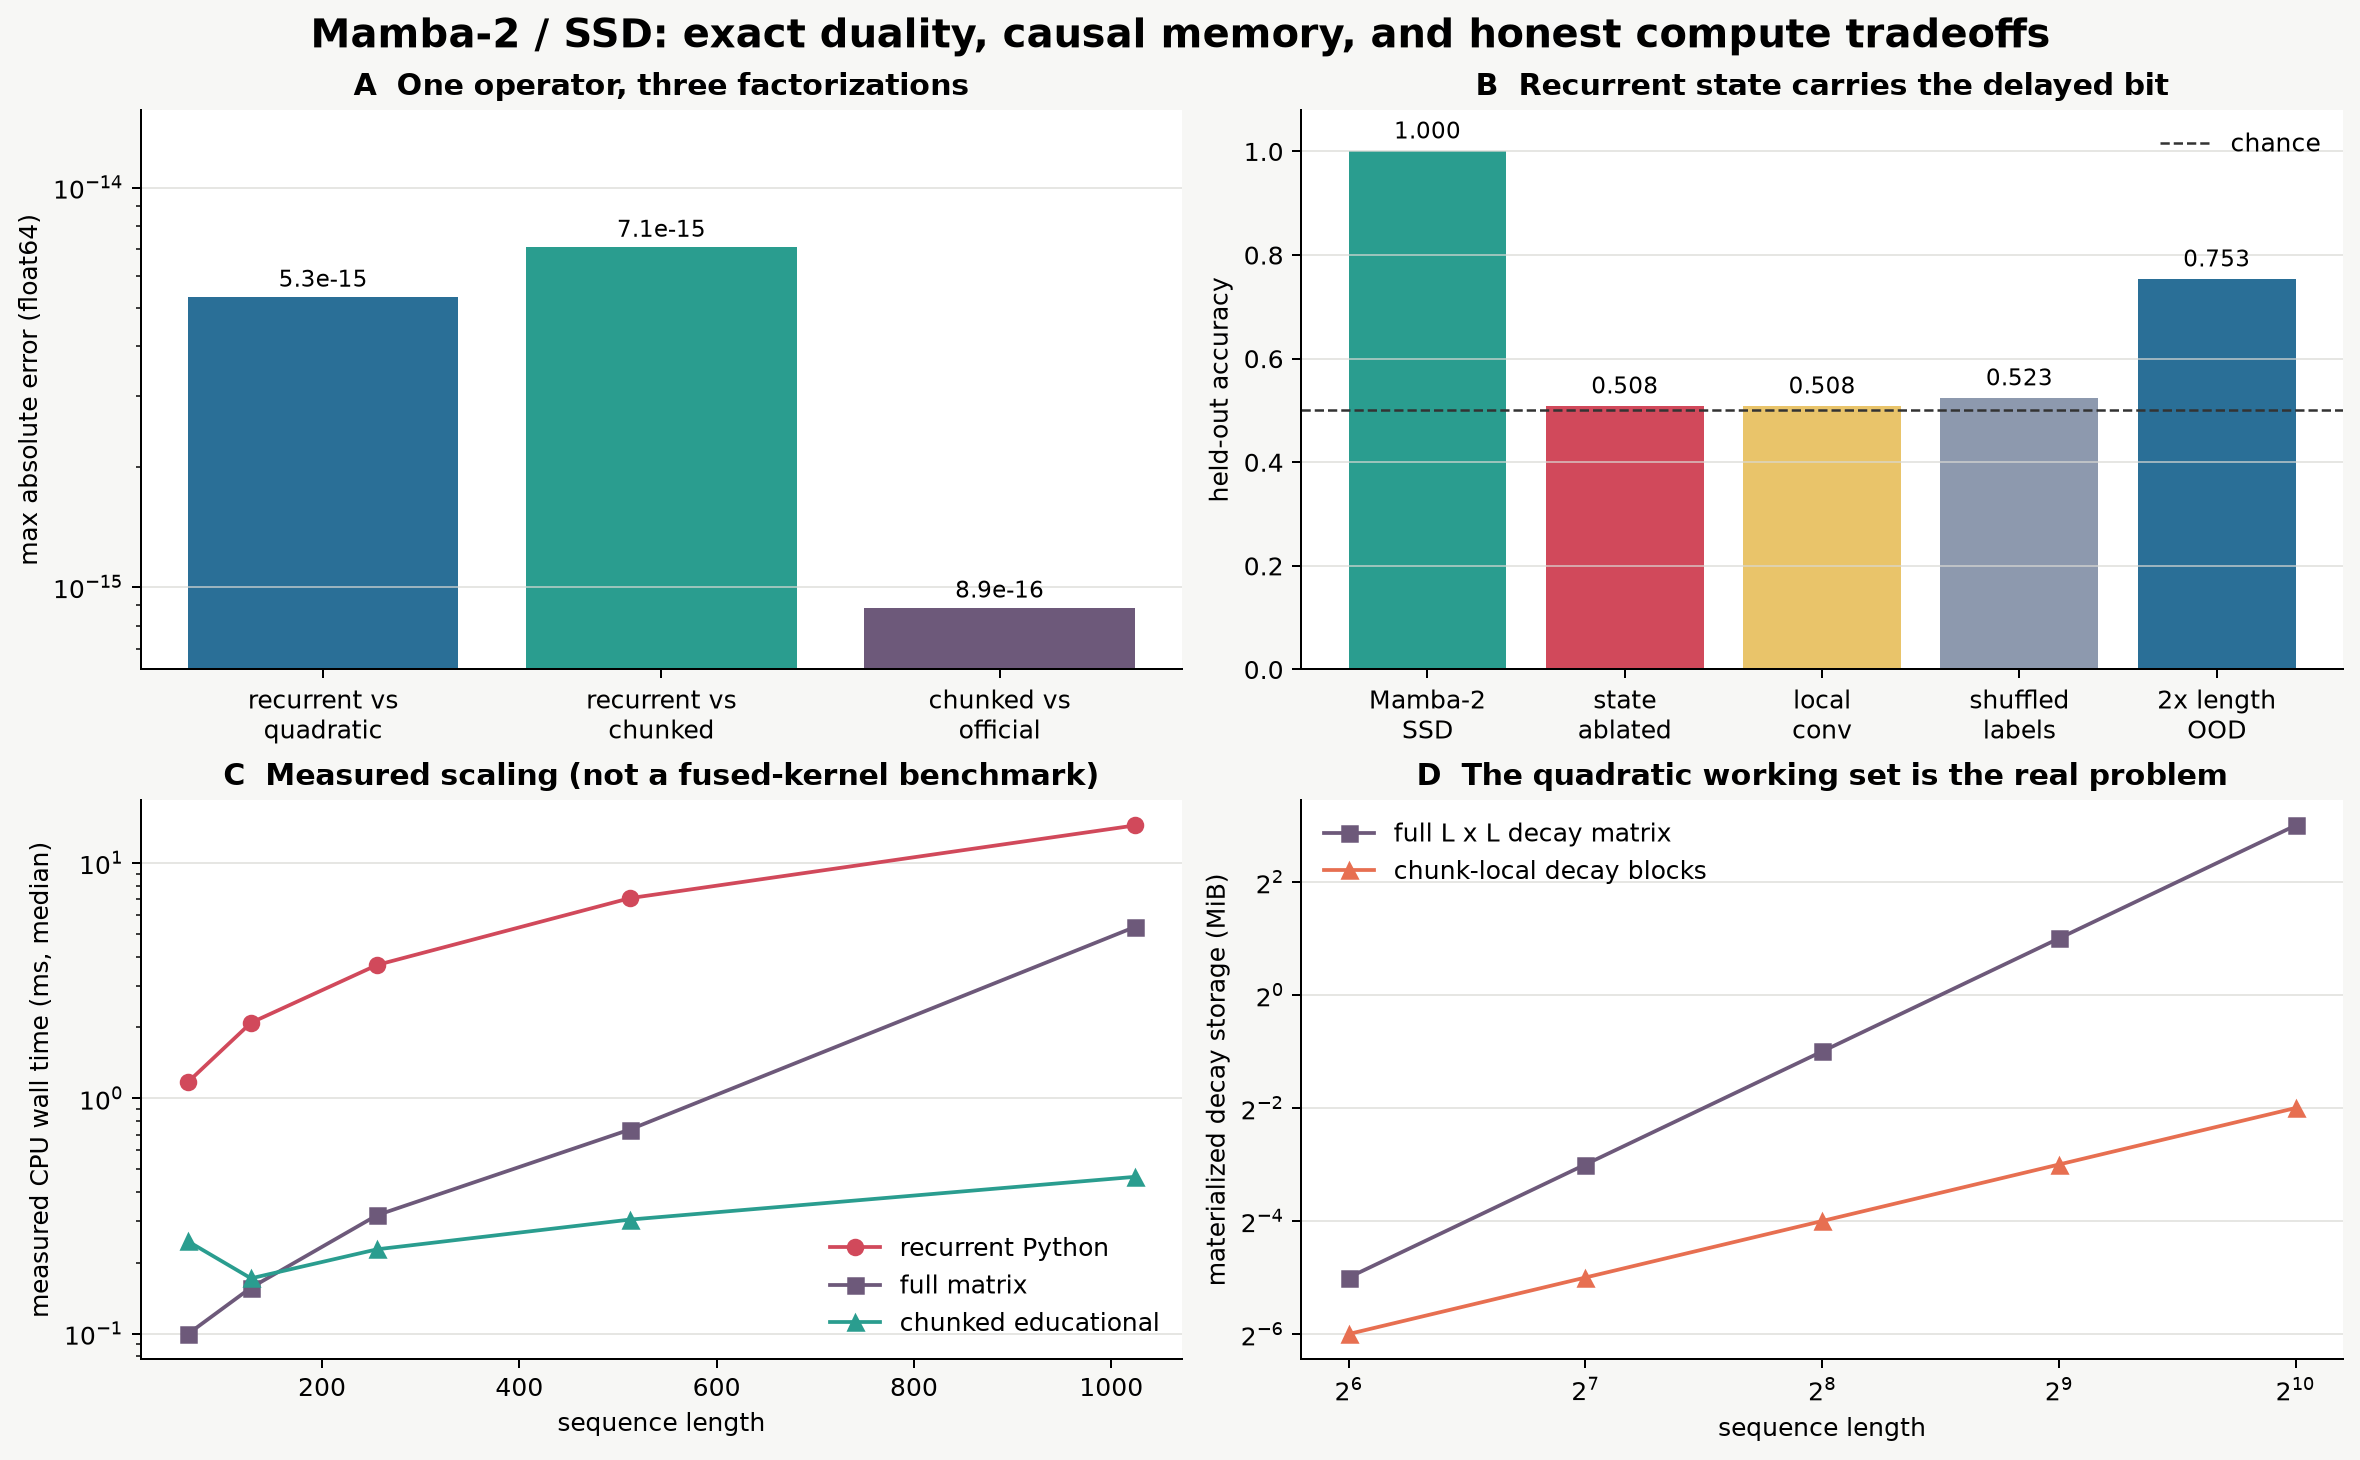

Numerical parity: {'recurrent_quadratic_max_abs_diff': 5.329070518200751e-15, 'recurrent_chunked_max_abs_diff': 7.105427357601002e-15, 'final_state_max_abs_diff': 1.7763568394002505e-15}
Official Listing 1 parity: {'output_max_abs_diff': 8.881784197001252e-16, 'final_state_max_abs_diff': 4.440892098500626e-16}
Held-out accuracies:
  Mamba-2 SSD       1.000
  state ablated     0.508
  local convolution 0.508
  shuffled labels   0.523
  doubled length    0.753


In [13]:
parity = exact_parity_metrics(length=48, chunk_size=8)
official_parity = official_ssd_reference_parity(length=32, chunk_size=8)
recall_result = run_delayed_recall_experiment(steps=100)
tests.test_delayed_recall_scientific_controls(recall_result)
scaling_result = measure_ssd_scaling((64, 128, 256, 512, 1024), chunk_size=32, repeats=3)

signature_path = root_dir / "chapter5_modern_architectures/instructions/assets/mamba2_ssd_signature.png"
make_signature_figure(parity, official_parity, recall_result, scaling_result, signature_path)
display(Image(filename=str(signature_path)))

print("Numerical parity:", parity)
print("Official Listing 1 parity:", official_parity)
print("Held-out accuracies:")
print(f"  Mamba-2 SSD       {recall_result.mamba_accuracy:.3f}")
print(f"  state ablated     {recall_result.state_ablated_accuracy:.3f}")
print(f"  local convolution {recall_result.local_conv_accuracy:.3f}")
print(f"  shuffled labels   {recall_result.shuffled_label_accuracy:.3f}")
print(f"  doubled length    {recall_result.ood_length_accuracy:.3f}")

<details><summary>Interpretation - what the signature result says</summary>

The recurrence, full matrix, chunked factorization, and official Listing 1 implementation agree to float64 rounding error. The learned model is not merely using its local convolution: removing recurrent carry collapses held-out accuracy to chance, as do the finite-convolution and shuffled-label controls. Doubled-length accuracy is a stress test and may be lower than in-distribution accuracy; report it as extrapolation evidence, not a theorem.

The CPU timing panel often makes the unfused chunked code look slower than the Python recurrence at these small sizes. That is a useful negative result. SSD's systems claim concerns large, fused, hardware-aware kernels; the memory panel is the portable structural result you can already verify here.

</details>

## Try It Yourself

Change `chunk_size` below. Exact outputs should not change, but intermediate memory and CPU timing will. Then change `d_state` in `make_ssd_inputs`: parity should survive while the recurrent cache grows linearly in state dimension.

In [14]:
X_play, A_play, B_play, C_play = make_ssd_inputs(length=72, d_state=7, seed=21)
oracle_play, _ = ssd_recurrent(X_play, A_play, B_play, C_play)
for chunk_size in (4, 8, 16, 24):
    candidate, _ = ssd_chunked(X_play, A_play, B_play, C_play, chunk_size)
    print(f"chunk={chunk_size:2d} max error={(candidate-oracle_play).abs().max().item():.2e}")

chunk= 4 max error=7.11e-15
chunk= 8 max error=8.88e-15
chunk=16 max error=7.11e-15
chunk=24 max error=7.11e-15


## Bonus - Anomaly Hunt

Search for regimes where an implementation that usually passes stops passing:

1. Compare stable segment sums with `cumsum[..., :, None] - cumsum[..., None, :]` after adding a large constant offset in float32.
2. Sweep chunk sizes that do not divide sequence length and verify the final cache as well as outputs.
3. Train on length 32 and plot accuracy at lengths 16, 32, 64, 128. Does the learned decay extrapolate monotonically?
4. Increase negative `A` magnitude until float16 underflow zeros long-range transitions. Is the chunked path still close to the recurrent path in float32?

A surprising mismatch is not something to smooth over. Minimize it to a small tensor fixture and decide whether the bug is indexing, padding, precision, or an invalid claim.

## Paper and official checkpoint connection

Read [Transformers are SSMs](https://arxiv.org/abs/2405.21060), especially the semiseparable matrix and SSD algorithm, alongside the official repository's [`ssd_minimal.py`](https://github.com/state-spaces/mamba/blob/main/mamba_ssm/modules/ssd_minimal.py) and [`mamba2_simple.py`](https://github.com/state-spaces/mamba/blob/main/mamba_ssm/modules/mamba2_simple.py).

The pinned release target is [`state-spaces/mamba2-130m`](https://huggingface.co/state-spaces/mamba2-130m) at commit `3a5aea0...`. The CPU learner path downloads only its configuration. The strict CUDA hook downloads the released weights, executes the 130M model, and compares our operator with the official fused SSD kernel.

In [15]:
def official_checkpoint_manifest() -> dict[str, Any]:
    """Read the pinned official Mamba-2 config without downloading its weights."""

    from huggingface_hub import hf_hub_download

    config_path = hf_hub_download(
        REAL_MAMBA2_MODEL_ID,
        "config.json",
        revision=REAL_MAMBA2_REVISION,
    )
    config = json.loads(Path(config_path).read_text(encoding="utf-8"))
    return {
        "model_id": REAL_MAMBA2_MODEL_ID,
        "revision": REAL_MAMBA2_REVISION,
        "d_model": config["d_model"],
        "n_layer": config["n_layer"],
        "vocab_size": config["vocab_size"],
        "ssm_layer": config["ssm_cfg"]["layer"],
    }

print(official_checkpoint_manifest())

{'model_id': 'state-spaces/mamba2-130m', 'revision': '3a5aea0c25d0fb43cc360e2c2aac82c26e3eed49', 'd_model': 768, 'n_layer': 24, 'vocab_size': 50277, 'ssm_layer': 'Mamba2'}


### Exercise 10 - gradients, a stacked LM, and matched architectural controls

> **Difficulty:** 🔴🔴🔴🔴⚪  
> **Purpose:** Finish the architecture rather than stopping at one block. Differentiate all three SSD schedules, stack cached blocks into a token LM, and instantiate real attention and Mamba-1 controls within ten percent of the Mamba-2 block's parameter count.

<details><summary>Expected output</summary>

```text
recurrent/quadratic gradient error < 1e-11
recurrent/chunked gradient error   < 1e-11
stacked LM full/cache logits error < 2e-6
parameter counts: Mamba-2 680, attention 624, Mamba-1 684
```

</details>

<details><summary>Help - common bug</summary>

The stacked cache is a list with one convolution state and one SSD state per layer. A single shared cache silently mixes different residual-stream representations. For the controls, count every trainable tensor; matching only projection matrices is not parameter matching.

</details>

<details><summary>Interpretation</summary>

Gradient parity establishes that training sees the same operator, not merely similar forward values. The matched controls prevent a capacity confound. They are runnable architectural controls; the exact linear-attention dual already established why a correct attention-like form should agree rather than fail.

</details>

<details><summary>Solution</summary>

```python
def exact_gradient_parity_metrics(seed: int = 17, device: str | t.device = "cpu") -> dict[str, float]:
    """Compare gradients from the recurrent, quadratic, and chunked schedules."""

    base = make_ssd_inputs(length=12, seed=seed, device=device)
    variants = [tuple(value.clone().requires_grad_() for value in base) for _ in range(3)]
    recurrent = ssd_recurrent(*variants[0])[0]
    quadratic = ssd_quadratic(*variants[1])
    chunked = ssd_chunked(*variants[2], chunk_size=4)[0]
    gradients = [
        t.autograd.grad(output.square().mean(), inputs)
        for output, inputs in zip((recurrent, quadratic, chunked), variants, strict=True)
    ]

    def difference(left: tuple[t.Tensor, ...], right: tuple[t.Tensor, ...]) -> float:
        return max(float((a - b).abs().max().detach()) for a, b in zip(left, right, strict=True))

    return {
        "recurrent_quadratic_gradient_max_abs_diff": difference(gradients[0], gradients[1]),
        "recurrent_chunked_gradient_max_abs_diff": difference(gradients[0], gradients[2]),
    }


class TinyStackedMamba2LM(nn.Module):
    """A small token LM built from the same learner-authored cached blocks."""

    def __init__(self, vocab_size: int = 47, n_layers: int = 2, config: Mamba2Config | None = None):
        super().__init__()
        self.config = config or Mamba2Config()
        self.embedding = nn.Embedding(vocab_size, self.config.d_model)
        self.layers = nn.ModuleList(
            [Mamba2BlockFromScratch(self.config) for _ in range(n_layers)]
        )
        self.final_norm = nn.RMSNorm(self.config.d_model)
        self.lm_head = nn.Linear(self.config.d_model, vocab_size, bias=False)

    def forward(self, input_ids: t.Tensor) -> t.Tensor:
        hidden = self.embedding(input_ids)
        for layer in self.layers:
            hidden = layer(hidden)
        return self.lm_head(self.final_norm(hidden))

    def forward_recurrent(self, input_ids: t.Tensor) -> tuple[t.Tensor, list[Mamba2Cache]]:
        batch = input_ids.shape[0]
        caches = [
            layer.allocate_cache(
                batch,
                device=input_ids.device,
                dtype=self.embedding.weight.dtype,
            )
            for layer in self.layers
        ]
        logits = []
        for position in range(input_ids.shape[1]):
            hidden = self.embedding(input_ids[:, position])
            next_caches = []
            for layer, cache in zip(self.layers, caches, strict=True):
                hidden, cache = layer.step(hidden, cache)
                next_caches.append(cache)
            caches = next_caches
            logits.append(self.lm_head(self.final_norm(hidden)))
        return t.cat(logits, dim=1), caches


class TinyCausalAttentionControl(nn.Module):
    """A real Transformer-style causal block near the learner Mamba-2 parameter count."""

    def __init__(self, d_model: int = 12, n_heads: int = 4):
        super().__init__()
        if d_model % n_heads:
            raise ValueError("n_heads must divide d_model")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.norm = nn.RMSNorm(d_model)
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=True)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        batch, length, d_model = inputs.shape
        q, k, v = self.qkv(self.norm(inputs)).chunk(3, dim=-1)
        q, k, v = [
            value.reshape(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
            for value in (q, k, v)
        ]
        scores = t.einsum("bhtp,bhsp->bhts", q, k) / math.sqrt(self.head_dim)
        future = t.triu(t.ones(length, length, dtype=t.bool, device=inputs.device), diagonal=1)
        pattern = scores.masked_fill(future, -t.inf).softmax(dim=-1)
        values = t.einsum("bhts,bhsp->bhtp", pattern, v)
        values = values.transpose(1, 2).reshape(batch, length, d_model)
        return inputs + self.out_proj(values)


class TinyMamba1Control(nn.Module):
    """A runnable Mamba-1-style block with channel-dependent transitions."""

    def __init__(self, d_model: int = 12, d_state: int = 4, d_conv: int = 3):
        super().__init__()
        self.d_model, self.d_state = d_model, d_state
        self.norm = nn.RMSNorm(d_model)
        self.in_proj = nn.Linear(d_model, 2 * d_model, bias=False)
        self.conv1d = nn.Conv1d(d_model, d_model, d_conv, groups=d_model, bias=True)
        self.x_proj = nn.Linear(d_model, 1 + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(1, d_model, bias=True)
        self.A_log = nn.Parameter(t.arange(1, d_state + 1).float().log().repeat(d_model, 1))
        self.D = nn.Parameter(t.ones(d_model))
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        X, gate = self.in_proj(self.norm(inputs)).chunk(2, dim=-1)
        X = F.silu(causal_depthwise_conv1d(X, self.conv1d.weight[:, 0], self.conv1d.bias))
        raw_dt, B, C = self.x_proj(X).split([1, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(raw_dt))
        state = X.new_zeros(X.shape[0], self.d_model, self.d_state)
        outputs = []
        for position in range(X.shape[1]):
            decay = (-self.A_log.exp()[None] * dt[:, position, :, None]).exp()
            state = decay * state + X[:, position, :, None] * dt[:, position, :, None] * B[:, position, None]
            outputs.append((state * C[:, position, None]).sum(dim=-1))
        mixed = t.stack(outputs, dim=1) + self.D * X
        return inputs + self.out_proj(mixed * F.silu(gate))


def parameter_matched_control_counts() -> dict[str, int]:
    modules = {
        "Mamba-2": Mamba2BlockFromScratch(Mamba2Config()),
        "causal attention": TinyCausalAttentionControl(),
        "Mamba-1": TinyMamba1Control(),
    }
    return {
        name: sum(parameter.numel() for parameter in module.parameters())
        for name, module in modules.items()
    }

tests.test_recurrent_quadratic_chunked_gradient_parity(exact_gradient_parity_metrics)
tests.test_tiny_stacked_lm_full_vs_recurrent_cache(TinyStackedMamba2LM)
tests.test_parameter_matched_attention_and_mamba1_controls(
    parameter_matched_control_counts, TinyCausalAttentionControl, TinyMamba1Control
)
```

</details>

In [16]:
def exact_gradient_parity_metrics(seed: int = 17, device: str | t.device = "cpu") -> dict[str, float]:
    """Compare gradients from the recurrent, quadratic, and chunked schedules."""

    base = make_ssd_inputs(length=12, seed=seed, device=device)
    variants = [tuple(value.clone().requires_grad_() for value in base) for _ in range(3)]
    recurrent = ssd_recurrent(*variants[0])[0]
    quadratic = ssd_quadratic(*variants[1])
    chunked = ssd_chunked(*variants[2], chunk_size=4)[0]
    gradients = [
        t.autograd.grad(output.square().mean(), inputs)
        for output, inputs in zip((recurrent, quadratic, chunked), variants, strict=True)
    ]

    def difference(left: tuple[t.Tensor, ...], right: tuple[t.Tensor, ...]) -> float:
        return max(float((a - b).abs().max().detach()) for a, b in zip(left, right, strict=True))

    return {
        "recurrent_quadratic_gradient_max_abs_diff": difference(gradients[0], gradients[1]),
        "recurrent_chunked_gradient_max_abs_diff": difference(gradients[0], gradients[2]),
    }


class TinyStackedMamba2LM(nn.Module):
    """A small token LM built from the same learner-authored cached blocks."""

    def __init__(self, vocab_size: int = 47, n_layers: int = 2, config: Mamba2Config | None = None):
        super().__init__()
        self.config = config or Mamba2Config()
        self.embedding = nn.Embedding(vocab_size, self.config.d_model)
        self.layers = nn.ModuleList(
            [Mamba2BlockFromScratch(self.config) for _ in range(n_layers)]
        )
        self.final_norm = nn.RMSNorm(self.config.d_model)
        self.lm_head = nn.Linear(self.config.d_model, vocab_size, bias=False)

    def forward(self, input_ids: t.Tensor) -> t.Tensor:
        hidden = self.embedding(input_ids)
        for layer in self.layers:
            hidden = layer(hidden)
        return self.lm_head(self.final_norm(hidden))

    def forward_recurrent(self, input_ids: t.Tensor) -> tuple[t.Tensor, list[Mamba2Cache]]:
        batch = input_ids.shape[0]
        caches = [
            layer.allocate_cache(
                batch,
                device=input_ids.device,
                dtype=self.embedding.weight.dtype,
            )
            for layer in self.layers
        ]
        logits = []
        for position in range(input_ids.shape[1]):
            hidden = self.embedding(input_ids[:, position])
            next_caches = []
            for layer, cache in zip(self.layers, caches, strict=True):
                hidden, cache = layer.step(hidden, cache)
                next_caches.append(cache)
            caches = next_caches
            logits.append(self.lm_head(self.final_norm(hidden)))
        return t.cat(logits, dim=1), caches


class TinyCausalAttentionControl(nn.Module):
    """A real Transformer-style causal block near the learner Mamba-2 parameter count."""

    def __init__(self, d_model: int = 12, n_heads: int = 4):
        super().__init__()
        if d_model % n_heads:
            raise ValueError("n_heads must divide d_model")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.norm = nn.RMSNorm(d_model)
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=True)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        batch, length, d_model = inputs.shape
        q, k, v = self.qkv(self.norm(inputs)).chunk(3, dim=-1)
        q, k, v = [
            value.reshape(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
            for value in (q, k, v)
        ]
        scores = t.einsum("bhtp,bhsp->bhts", q, k) / math.sqrt(self.head_dim)
        future = t.triu(t.ones(length, length, dtype=t.bool, device=inputs.device), diagonal=1)
        pattern = scores.masked_fill(future, -t.inf).softmax(dim=-1)
        values = t.einsum("bhts,bhsp->bhtp", pattern, v)
        values = values.transpose(1, 2).reshape(batch, length, d_model)
        return inputs + self.out_proj(values)


class TinyMamba1Control(nn.Module):
    """A runnable Mamba-1-style block with channel-dependent transitions."""

    def __init__(self, d_model: int = 12, d_state: int = 4, d_conv: int = 3):
        super().__init__()
        self.d_model, self.d_state = d_model, d_state
        self.norm = nn.RMSNorm(d_model)
        self.in_proj = nn.Linear(d_model, 2 * d_model, bias=False)
        self.conv1d = nn.Conv1d(d_model, d_model, d_conv, groups=d_model, bias=True)
        self.x_proj = nn.Linear(d_model, 1 + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(1, d_model, bias=True)
        self.A_log = nn.Parameter(t.arange(1, d_state + 1).float().log().repeat(d_model, 1))
        self.D = nn.Parameter(t.ones(d_model))
        self.out_proj = nn.Linear(d_model, d_model, bias=False)

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        X, gate = self.in_proj(self.norm(inputs)).chunk(2, dim=-1)
        X = F.silu(causal_depthwise_conv1d(X, self.conv1d.weight[:, 0], self.conv1d.bias))
        raw_dt, B, C = self.x_proj(X).split([1, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(raw_dt))
        state = X.new_zeros(X.shape[0], self.d_model, self.d_state)
        outputs = []
        for position in range(X.shape[1]):
            decay = (-self.A_log.exp()[None] * dt[:, position, :, None]).exp()
            state = decay * state + X[:, position, :, None] * dt[:, position, :, None] * B[:, position, None]
            outputs.append((state * C[:, position, None]).sum(dim=-1))
        mixed = t.stack(outputs, dim=1) + self.D * X
        return inputs + self.out_proj(mixed * F.silu(gate))


def parameter_matched_control_counts() -> dict[str, int]:
    modules = {
        "Mamba-2": Mamba2BlockFromScratch(Mamba2Config()),
        "causal attention": TinyCausalAttentionControl(),
        "Mamba-1": TinyMamba1Control(),
    }
    return {
        name: sum(parameter.numel() for parameter in module.parameters())
        for name, module in modules.items()
    }

tests.test_recurrent_quadratic_chunked_gradient_parity(exact_gradient_parity_metrics)
tests.test_tiny_stacked_lm_full_vs_recurrent_cache(TinyStackedMamba2LM)
tests.test_parameter_matched_attention_and_mamba1_controls(
    parameter_matched_control_counts, TinyCausalAttentionControl, TinyMamba1Control
)

All tests in `test_recurrent_quadratic_chunked_gradient_parity` passed!
All tests in `test_tiny_stacked_lm_full_vs_recurrent_cache` passed!
All tests in `test_parameter_matched_attention_and_mamba1_controls` passed!


In [17]:
gradient_metrics = exact_gradient_parity_metrics()
print("gradient parity:", gradient_metrics)
assert max(gradient_metrics.values()) < 1e-11

t.manual_seed(19)
tiny_lm = TinyStackedMamba2LM(vocab_size=47, n_layers=2).eval()
tiny_ids = t.randint(0, 47, (2, 16))
with t.inference_mode():
    full_logits = tiny_lm(tiny_ids)
    cache_logits, layer_caches = tiny_lm.forward_recurrent(tiny_ids)
cache_error = float((full_logits - cache_logits).abs().max())
counts = parameter_matched_control_counts()
print("stacked LM logits:", tuple(full_logits.shape), "| cache error:", cache_error)
print("parameter-matched controls:", counts)
assert cache_error < 2e-6 and len(layer_caches) == 2
assert max(abs(value - counts["Mamba-2"]) / counts["Mamba-2"] for value in counts.values()) < .10

gradient parity: {'recurrent_quadratic_gradient_max_abs_diff': 1.7763568394002505e-15, 'recurrent_chunked_gradient_max_abs_diff': 3.552713678800501e-15}
stacked LM logits: (2, 16, 47) | cache error: 3.5762786865234375e-07
parameter-matched controls: {'Mamba-2': 680, 'causal attention': 624, 'Mamba-1': 684}


### Exercise 11 - map the released Mamba-2 130M model

> **Difficulty:** 🔴🔴🔴🔴🔴  
> **Purpose:** Convert the actual pinned release into the learner architecture and compare every layer against an independent Transformers Mamba-2 implementation on two real tokenized prompts.

The native release and Transformers schemas differ in one name only: `backbone.embedding.weight` versus `backbone.embeddings.weight`. We promote the released fp16 tensors to float32 for this CPU comparison so 24 layers of fp16 rounding do not obscure implementation parity.

<details><summary>Expected output</summary>

```text
mapped tensors:       219
hidden states:        25
hidden max |diff|:    < 0.002
logits max |diff|:    < 0.0005
top-1 agreement:      1.0
top token IDs:        (320, 253) in both models
```

</details>

<details><summary>Help - common bug</summary>

The tokenizer vocabulary is 50277, but the released embedding and unembedding matrices are padded to 50288. The official mixer gates **before** RMS normalization; the earlier compact teaching block uses a simpler arrangement and cannot accept these weights unchanged.

</details>

<details><summary>Interpretation</summary>

Strict loading proves architectural coverage: no tensor is ignored. Hidden-state parity localizes agreement throughout the 24-layer computation, while final-logit and top-token parity rule out a merely shape-correct model.

</details>

<details><summary>Solution</summary>

```python
import gc

REAL_MAMBA2_PROMPT_TOKEN_IDS = ((46, 31834, 3210, 476), (510, 5798, 2206, 327))

@dataclass(frozen=True)
class ReleasedMamba2Config:
    vocab_size: int = 50288
    d_model: int = 768
    n_layers: int = 24
    d_inner: int = 1536
    n_heads: int = 24
    head_dim: int = 64
    d_state: int = 128
    n_groups: int = 1
    d_conv: int = 4
    chunk_size: int = 8
    eps: float = 1e-5

    @property
    def conv_dim(self) -> int:
        return self.d_inner + 2 * self.n_groups * self.d_state

    @property
    def projection_size(self) -> int:
        return 2 * self.d_inner + 2 * self.n_groups * self.d_state + self.n_heads


class ReleasedRMSNorm(nn.Module):
    def __init__(self, width: int, eps: float = 1e-5):
        super().__init__()
        self.weight = nn.Parameter(t.ones(width))
        self.eps = eps

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        dtype = inputs.dtype
        values = inputs.float()
        values = values * t.rsqrt(values.square().mean(-1, keepdim=True) + self.eps)
        return self.weight * values.to(dtype)


class ReleasedGatedRMSNorm(nn.Module):
    def __init__(self, width: int, eps: float = 1e-5):
        super().__init__()
        self.weight = nn.Parameter(t.ones(width))
        self.eps = eps

    def forward(self, inputs: t.Tensor, gate: t.Tensor) -> t.Tensor:
        dtype = inputs.dtype
        values = inputs.float() * F.silu(gate.float())
        values = values * t.rsqrt(values.square().mean(-1, keepdim=True) + self.eps)
        return self.weight * values.to(dtype)


class ReleasedMamba2MixerFromScratch(nn.Module):
    """Faithful unfused Mamba-2 mixer matching the released 130M tensor schema."""

    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.config = config
        self.in_proj = nn.Linear(config.d_model, config.projection_size, bias=False)
        self.conv1d = nn.Conv1d(
            config.conv_dim,
            config.conv_dim,
            config.d_conv,
            groups=config.conv_dim,
            bias=True,
        )
        self.dt_bias = nn.Parameter(t.empty(config.n_heads))
        self.A_log = nn.Parameter(t.empty(config.n_heads))
        self.D = nn.Parameter(t.ones(config.n_heads))
        self.norm = ReleasedGatedRMSNorm(config.d_inner, config.eps)
        self.out_proj = nn.Linear(config.d_inner, config.d_model, bias=False)

    def forward(self, hidden: t.Tensor) -> t.Tensor:
        dtype = hidden.dtype
        gate, XBC, raw_dt = self.in_proj(hidden).split(
            [self.config.d_inner, self.config.conv_dim, self.config.n_heads], dim=-1
        )
        XBC = F.silu(causal_depthwise_conv1d(XBC, self.conv1d.weight[:, 0], self.conv1d.bias))
        X, B, C = XBC.split(
            [
                self.config.d_inner,
                self.config.n_groups * self.config.d_state,
                self.config.n_groups * self.config.d_state,
            ],
            dim=-1,
        )
        batch, length, _ = X.shape
        X = X.reshape(batch, length, self.config.n_heads, self.config.head_dim).float()
        B = B.reshape(batch, length, self.config.n_groups, self.config.d_state).float()
        C = C.reshape(batch, length, self.config.n_groups, self.config.d_state).float()
        dt = F.softplus(raw_dt + self.dt_bias).float()
        continuous_A = -self.A_log.float().exp()
        Y, _ = ssd_chunked(
            X * dt[..., None],
            continuous_A[None, None] * dt,
            B,
            C,
            self.config.chunk_size,
        )
        Y = Y + self.D.float()[None, None, :, None] * X
        Y = self.norm(Y.reshape(batch, length, self.config.d_inner), gate)
        return self.out_proj(Y.to(dtype))


class ReleasedMamba2BlockFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.norm = ReleasedRMSNorm(config.d_model, config.eps)
        self.mixer = ReleasedMamba2MixerFromScratch(config)

    def forward(self, hidden: t.Tensor) -> t.Tensor:
        residual = hidden.float()
        normalized = self.norm(hidden.to(self.norm.weight.dtype))
        return residual + self.mixer(normalized)


class ReleasedMamba2BackboneFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.embeddings = nn.Embedding(config.vocab_size, config.d_model)
        self.layers = nn.ModuleList(
            [ReleasedMamba2BlockFromScratch(config) for _ in range(config.n_layers)]
        )
        self.norm_f = ReleasedRMSNorm(config.d_model, config.eps)

    def forward(self, input_ids: t.Tensor) -> tuple[t.Tensor, tuple[t.Tensor, ...]]:
        hidden = self.embeddings(input_ids)
        hidden_states = []
        for layer in self.layers:
            hidden = layer(hidden)
            hidden_states.append(hidden)
        hidden = self.norm_f(hidden)
        hidden_states.append(hidden)
        return hidden, tuple(hidden_states)


class ReleasedMamba2LMFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.backbone = ReleasedMamba2BackboneFromScratch(config)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)

    def forward(self, input_ids: t.Tensor) -> tuple[t.Tensor, tuple[t.Tensor, ...]]:
        hidden, hidden_states = self.backbone(input_ids)
        logits = self.lm_head(hidden.to(self.lm_head.weight.dtype)).float()
        return logits, hidden_states


@dataclass(frozen=True)
class ReleasedCheckpointParity:
    mapped_tensor_count: int
    hidden_state_count: int
    hidden_max_abs_diff: float
    hidden_mean_abs_diff: float
    logits_max_abs_diff: float
    logits_mean_abs_diff: float
    top1_agreement: float
    reference_top_tokens: tuple[int, ...]
    learner_top_tokens: tuple[int, ...]


def native_to_released_state_dict(native: dict[str, t.Tensor]) -> dict[str, t.Tensor]:
    """Convert the release's single native-vs-HF embedding name difference."""

    mapped = {
        ("backbone.embeddings.weight" if key == "backbone.embedding.weight" else key): value.float()
        for key, value in native.items()
    }
    if len(mapped) != 219:
        raise AssertionError(f"expected 219 released tensors, found {len(mapped)}")
    return mapped


def _load_released_state_dict() -> dict[str, t.Tensor]:
    from huggingface_hub import snapshot_download

    snapshot = snapshot_download(
        REAL_MAMBA2_MODEL_ID,
        revision=REAL_MAMBA2_REVISION,
        allow_patterns=["config.json", "pytorch_model.bin"],
        local_files_only=True,
    )
    native = t.load(
        Path(snapshot) / "pytorch_model.bin",
        map_location="cpu",
        weights_only=True,
        mmap=True,
    )
    return native_to_released_state_dict(native)


def _released_hf_config():
    from transformers import Mamba2Config as HFMamba2Config

    return HFMamba2Config(
        vocab_size=50288,
        hidden_size=768,
        num_hidden_layers=24,
        expand=2,
        num_heads=24,
        head_dim=64,
        state_size=128,
        n_groups=1,
        conv_kernel=4,
        chunk_size=8,
        tie_word_embeddings=True,
        residual_in_fp32=True,
        use_bias=False,
        use_conv_bias=True,
    )


def verify_released_mamba2_parity(device: str | t.device = "cpu") -> ReleasedCheckpointParity:
    """Strictly map the 130M release and compare two independent implementations."""

    from transformers import Mamba2ForCausalLM

    state = _load_released_state_dict()
    with t.device("meta"):
        learner = ReleasedMamba2LMFromScratch(ReleasedMamba2Config())
        reference = Mamba2ForCausalLM(_released_hf_config())
    learner.load_state_dict(state, strict=True, assign=True)
    reference.load_state_dict(state, strict=True, assign=True)
    learner = learner.to(device).eval()
    reference = reference.to(device).eval()
    input_ids = t.tensor(REAL_MAMBA2_PROMPT_TOKEN_IDS, dtype=t.long, device=device)
    with t.inference_mode():
        learner_logits, learner_hidden = learner(input_ids)
        reference_output = reference(
            input_ids,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True,
        )
    hidden_differences = [
        (left.float() - right.float()).abs()
        for left, right in zip(learner_hidden, reference_output.hidden_states, strict=True)
    ]
    logits_difference = (learner_logits - reference_output.logits).abs()
    learner_top = learner_logits[:, -1].argmax(-1)
    reference_top = reference_output.logits[:, -1].argmax(-1)
    result = ReleasedCheckpointParity(
        mapped_tensor_count=len(state),
        hidden_state_count=len(hidden_differences),
        hidden_max_abs_diff=max(float(value.max()) for value in hidden_differences),
        hidden_mean_abs_diff=max(float(value.mean()) for value in hidden_differences),
        logits_max_abs_diff=float(logits_difference.max()),
        logits_mean_abs_diff=float(logits_difference.mean()),
        top1_agreement=float((learner_top == reference_top).float().mean()),
        reference_top_tokens=tuple(reference_top.cpu().tolist()),
        learner_top_tokens=tuple(learner_top.cpu().tolist()),
    )
    del learner, reference, state
    gc.collect()
    if t.cuda.is_available():
        t.cuda.empty_cache()
    return result
```

</details>

In [18]:
import gc

REAL_MAMBA2_PROMPT_TOKEN_IDS = ((46, 31834, 3210, 476), (510, 5798, 2206, 327))

@dataclass(frozen=True)
class ReleasedMamba2Config:
    vocab_size: int = 50288
    d_model: int = 768
    n_layers: int = 24
    d_inner: int = 1536
    n_heads: int = 24
    head_dim: int = 64
    d_state: int = 128
    n_groups: int = 1
    d_conv: int = 4
    chunk_size: int = 8
    eps: float = 1e-5

    @property
    def conv_dim(self) -> int:
        return self.d_inner + 2 * self.n_groups * self.d_state

    @property
    def projection_size(self) -> int:
        return 2 * self.d_inner + 2 * self.n_groups * self.d_state + self.n_heads


class ReleasedRMSNorm(nn.Module):
    def __init__(self, width: int, eps: float = 1e-5):
        super().__init__()
        self.weight = nn.Parameter(t.ones(width))
        self.eps = eps

    def forward(self, inputs: t.Tensor) -> t.Tensor:
        dtype = inputs.dtype
        values = inputs.float()
        values = values * t.rsqrt(values.square().mean(-1, keepdim=True) + self.eps)
        return self.weight * values.to(dtype)


class ReleasedGatedRMSNorm(nn.Module):
    def __init__(self, width: int, eps: float = 1e-5):
        super().__init__()
        self.weight = nn.Parameter(t.ones(width))
        self.eps = eps

    def forward(self, inputs: t.Tensor, gate: t.Tensor) -> t.Tensor:
        dtype = inputs.dtype
        values = inputs.float() * F.silu(gate.float())
        values = values * t.rsqrt(values.square().mean(-1, keepdim=True) + self.eps)
        return self.weight * values.to(dtype)


class ReleasedMamba2MixerFromScratch(nn.Module):
    """Faithful unfused Mamba-2 mixer matching the released 130M tensor schema."""

    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.config = config
        self.in_proj = nn.Linear(config.d_model, config.projection_size, bias=False)
        self.conv1d = nn.Conv1d(
            config.conv_dim,
            config.conv_dim,
            config.d_conv,
            groups=config.conv_dim,
            bias=True,
        )
        self.dt_bias = nn.Parameter(t.empty(config.n_heads))
        self.A_log = nn.Parameter(t.empty(config.n_heads))
        self.D = nn.Parameter(t.ones(config.n_heads))
        self.norm = ReleasedGatedRMSNorm(config.d_inner, config.eps)
        self.out_proj = nn.Linear(config.d_inner, config.d_model, bias=False)

    def forward(self, hidden: t.Tensor) -> t.Tensor:
        dtype = hidden.dtype
        gate, XBC, raw_dt = self.in_proj(hidden).split(
            [self.config.d_inner, self.config.conv_dim, self.config.n_heads], dim=-1
        )
        XBC = F.silu(causal_depthwise_conv1d(XBC, self.conv1d.weight[:, 0], self.conv1d.bias))
        X, B, C = XBC.split(
            [
                self.config.d_inner,
                self.config.n_groups * self.config.d_state,
                self.config.n_groups * self.config.d_state,
            ],
            dim=-1,
        )
        batch, length, _ = X.shape
        X = X.reshape(batch, length, self.config.n_heads, self.config.head_dim).float()
        B = B.reshape(batch, length, self.config.n_groups, self.config.d_state).float()
        C = C.reshape(batch, length, self.config.n_groups, self.config.d_state).float()
        dt = F.softplus(raw_dt + self.dt_bias).float()
        continuous_A = -self.A_log.float().exp()
        Y, _ = ssd_chunked(
            X * dt[..., None],
            continuous_A[None, None] * dt,
            B,
            C,
            self.config.chunk_size,
        )
        Y = Y + self.D.float()[None, None, :, None] * X
        Y = self.norm(Y.reshape(batch, length, self.config.d_inner), gate)
        return self.out_proj(Y.to(dtype))


class ReleasedMamba2BlockFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.norm = ReleasedRMSNorm(config.d_model, config.eps)
        self.mixer = ReleasedMamba2MixerFromScratch(config)

    def forward(self, hidden: t.Tensor) -> t.Tensor:
        residual = hidden.float()
        normalized = self.norm(hidden.to(self.norm.weight.dtype))
        return residual + self.mixer(normalized)


class ReleasedMamba2BackboneFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.embeddings = nn.Embedding(config.vocab_size, config.d_model)
        self.layers = nn.ModuleList(
            [ReleasedMamba2BlockFromScratch(config) for _ in range(config.n_layers)]
        )
        self.norm_f = ReleasedRMSNorm(config.d_model, config.eps)

    def forward(self, input_ids: t.Tensor) -> tuple[t.Tensor, tuple[t.Tensor, ...]]:
        hidden = self.embeddings(input_ids)
        hidden_states = []
        for layer in self.layers:
            hidden = layer(hidden)
            hidden_states.append(hidden)
        hidden = self.norm_f(hidden)
        hidden_states.append(hidden)
        return hidden, tuple(hidden_states)


class ReleasedMamba2LMFromScratch(nn.Module):
    def __init__(self, config: ReleasedMamba2Config):
        super().__init__()
        self.backbone = ReleasedMamba2BackboneFromScratch(config)
        self.lm_head = nn.Linear(config.d_model, config.vocab_size, bias=False)

    def forward(self, input_ids: t.Tensor) -> tuple[t.Tensor, tuple[t.Tensor, ...]]:
        hidden, hidden_states = self.backbone(input_ids)
        logits = self.lm_head(hidden.to(self.lm_head.weight.dtype)).float()
        return logits, hidden_states


@dataclass(frozen=True)
class ReleasedCheckpointParity:
    mapped_tensor_count: int
    hidden_state_count: int
    hidden_max_abs_diff: float
    hidden_mean_abs_diff: float
    logits_max_abs_diff: float
    logits_mean_abs_diff: float
    top1_agreement: float
    reference_top_tokens: tuple[int, ...]
    learner_top_tokens: tuple[int, ...]


def native_to_released_state_dict(native: dict[str, t.Tensor]) -> dict[str, t.Tensor]:
    """Convert the release's single native-vs-HF embedding name difference."""

    mapped = {
        ("backbone.embeddings.weight" if key == "backbone.embedding.weight" else key): value.float()
        for key, value in native.items()
    }
    if len(mapped) != 219:
        raise AssertionError(f"expected 219 released tensors, found {len(mapped)}")
    return mapped


def _load_released_state_dict() -> dict[str, t.Tensor]:
    from huggingface_hub import snapshot_download

    snapshot = snapshot_download(
        REAL_MAMBA2_MODEL_ID,
        revision=REAL_MAMBA2_REVISION,
        allow_patterns=["config.json", "pytorch_model.bin"],
        local_files_only=True,
    )
    native = t.load(
        Path(snapshot) / "pytorch_model.bin",
        map_location="cpu",
        weights_only=True,
        mmap=True,
    )
    return native_to_released_state_dict(native)


def _released_hf_config():
    from transformers import Mamba2Config as HFMamba2Config

    return HFMamba2Config(
        vocab_size=50288,
        hidden_size=768,
        num_hidden_layers=24,
        expand=2,
        num_heads=24,
        head_dim=64,
        state_size=128,
        n_groups=1,
        conv_kernel=4,
        chunk_size=8,
        tie_word_embeddings=True,
        residual_in_fp32=True,
        use_bias=False,
        use_conv_bias=True,
    )


def verify_released_mamba2_parity(device: str | t.device = "cpu") -> ReleasedCheckpointParity:
    """Strictly map the 130M release and compare two independent implementations."""

    from transformers import Mamba2ForCausalLM

    state = _load_released_state_dict()
    with t.device("meta"):
        learner = ReleasedMamba2LMFromScratch(ReleasedMamba2Config())
        reference = Mamba2ForCausalLM(_released_hf_config())
    learner.load_state_dict(state, strict=True, assign=True)
    reference.load_state_dict(state, strict=True, assign=True)
    learner = learner.to(device).eval()
    reference = reference.to(device).eval()
    input_ids = t.tensor(REAL_MAMBA2_PROMPT_TOKEN_IDS, dtype=t.long, device=device)
    with t.inference_mode():
        learner_logits, learner_hidden = learner(input_ids)
        reference_output = reference(
            input_ids,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True,
        )
    hidden_differences = [
        (left.float() - right.float()).abs()
        for left, right in zip(learner_hidden, reference_output.hidden_states, strict=True)
    ]
    logits_difference = (learner_logits - reference_output.logits).abs()
    learner_top = learner_logits[:, -1].argmax(-1)
    reference_top = reference_output.logits[:, -1].argmax(-1)
    result = ReleasedCheckpointParity(
        mapped_tensor_count=len(state),
        hidden_state_count=len(hidden_differences),
        hidden_max_abs_diff=max(float(value.max()) for value in hidden_differences),
        hidden_mean_abs_diff=max(float(value.mean()) for value in hidden_differences),
        logits_max_abs_diff=float(logits_difference.max()),
        logits_mean_abs_diff=float(logits_difference.mean()),
        top1_agreement=float((learner_top == reference_top).float().mean()),
        reference_top_tokens=tuple(reference_top.cpu().tolist()),
        learner_top_tokens=tuple(learner_top.cpu().tolist()),
    )
    del learner, reference, state
    gc.collect()
    if t.cuda.is_available():
        t.cuda.empty_cache()
    return result

In [19]:
released_parity = verify_released_mamba2_parity("cpu")
for name, value in released_parity.__dict__.items():
    print(f"{name:28s}", value)
assert released_parity.mapped_tensor_count == 219
assert released_parity.hidden_state_count == 25
assert released_parity.hidden_max_abs_diff < .002
assert released_parity.logits_max_abs_diff < 5e-4
assert released_parity.top1_agreement == 1.0
assert released_parity.reference_top_tokens == released_parity.learner_top_tokens

W0905 08:32:50.342000 547471 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0905 08:32:50.352000 547471 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Fetching ... files: 0it [00:00, ?it/s]

mapped_tensor_count          219
hidden_state_count           25
hidden_max_abs_diff          0.000732421875
hidden_mean_abs_diff         2.153784407710191e-05
logits_max_abs_diff          0.0001373291015625
logits_mean_abs_diff         3.001509867317509e-05
top1_agreement               1.0
reference_top_tokens         (320, 253)
learner_top_tokens           (320, 253)


## Release verification hooks

The supporting `verification_report.json` records pinned inputs and fresh CUDA
measurements from the release harness. The figures above are computed directly
from the implementations you wrote.

These functions are supporting release evidence, not the lesson's signature result. They are strict CUDA-only entry points: absence of CUDA, the fused official operator, or the pinned checkpoint is an error rather than a CPU fallback or skipped success.

In [20]:
def run_smoke_test(cpu: bool = True) -> dict[str, Any]:
    device = t.device("cpu") if cpu else _require_cuda()
    parity = exact_parity_metrics(device=device)
    official = official_ssd_reference_parity(device=device)
    gradients = exact_gradient_parity_metrics(device=device)
    t.manual_seed(4)
    block = Mamba2BlockFromScratch(Mamba2Config()).to(device).eval()
    inputs = t.randn(2, 19, block.config.d_model, device=device)
    full = block(inputs)
    cache = block.allocate_cache(2, device=device, dtype=inputs.dtype)
    steps = []
    with t.inference_mode():
        for position in range(inputs.shape[1]):
            output, cache = block.step(inputs[:, position], cache)
            steps.append(output)
    step_error = float((full - t.cat(steps, dim=1)).abs().max())
    lm = TinyStackedMamba2LM(vocab_size=47, n_layers=2).to(device).eval()
    token_ids = t.randint(0, 47, (2, 16), device=device)
    with t.inference_mode():
        full_logits = lm(token_ids)
        cached_logits, _ = lm.forward_recurrent(token_ids)
    lm_error = float((full_logits - cached_logits).abs().max())
    counts = parameter_matched_control_counts()
    count_error = max(abs(count / counts["Mamba-2"] - 1) for count in counts.values())
    return {
        "device": str(device),
        "parity": parity,
        "official_reference": official,
        "gradients": gradients,
        "official_listing_one_output_max_abs_diff": official["output_max_abs_diff"],
        "official_listing_one_state_max_abs_diff": official["final_state_max_abs_diff"],
        "cache_max_abs_diff": step_error,
        "stacked_lm_cache_max_abs_diff": lm_error,
        "parameter_matched_control_relative_error": count_error,
        "tests_passed": max(parity.values()) < 1e-11
        and max(official.values()) < 1e-11
        and max(gradients.values()) < 1e-11
        and step_error < 2e-6 and lm_error < 2e-6 and count_error < 0.1,
    }

def _require_cuda() -> t.device:
    if not t.cuda.is_available():
        raise RuntimeError("CUDA is required; this release hook has no CPU fallback")
    from triton import knobs

    if os.environ.get("TRITON_F32_DEFAULT") != "ieee" or knobs.language.fp32_default != "ieee":
        raise RuntimeError(
            "Start a fresh process/kernel with TRITON_F32_DEFAULT=ieee before importing "
            "Mamba. TF32 kernels do not satisfy the float32 implementation-parity contract."
        )
    if t.get_float32_matmul_precision() != "highest":
        raise RuntimeError("Set torch.set_float32_matmul_precision('highest') for IEEE parity")
    return t.device("cuda")


def _official_fused_operator_parity(device: t.device) -> dict[str, float]:
    from mamba_ssm.ops.triton.ssd_combined import mamba_chunk_scan_combined

    generator = t.Generator().manual_seed(7)
    batch, length, heads, head_dim, state = 2, 256, 4, 8, 8
    X = t.randn(batch, length, heads, head_dim, generator=generator).to(device)
    dt = (0.01 + 0.05 * t.rand(batch, length, heads, generator=generator)).to(device)
    A = (-t.exp(t.linspace(0.0, 1.0, heads))).to(device)
    B = t.randn(batch, length, 1, state, generator=generator).to(device)
    C = t.randn(batch, length, 1, state, generator=generator).to(device)
    with t.inference_mode():
        fused = mamba_chunk_scan_combined(X, dt, A, B, C, 64, D=None)
        ours, _ = ssd_chunked(X * dt[..., None], A * dt, B, C, 64)
    difference = (fused.float() - ours.float()).abs()
    return {
        "max_abs_diff": float(difference.max()),
        "mean_abs_diff": float(difference.mean()),
    }


def _official_checkpoint_preflight(device: t.device) -> dict[str, Any]:
    from huggingface_hub import snapshot_download
    from mamba_ssm.models.mixer_seq_simple import MambaLMHeadModel

    snapshot = snapshot_download(
        REAL_MAMBA2_MODEL_ID,
        revision=REAL_MAMBA2_REVISION,
        allow_patterns=["config.json", "pytorch_model.bin"],
    )
    model = MambaLMHeadModel.from_pretrained(
        snapshot,
        device=device,
        dtype=t.float16,
    ).eval()
    input_ids = t.tensor([[0, 17, 42, 9, 301, 11, 8, 2]], device=device)
    with t.inference_mode():
        logits = model(input_ids).logits.float()
        repeated = model(input_ids).logits.float()
    deterministic_error = float((logits - repeated).abs().max())
    result = {
        "logits_shape": list(logits.shape),
        "logits_std": float(logits.std()),
        "deterministic_max_abs_diff": deterministic_error,
        "finite": bool(t.isfinite(logits).all()),
    }
    del model, logits, repeated
    t.cuda.empty_cache()
    return result


def run_gpu_test(max_vram_gb: float = 24.0) -> dict[str, Any]:
    """Strict CUDA release test: fused operator plus pinned 130M checkpoint."""

    device = _require_cuda()
    started = time.perf_counter()
    t.cuda.empty_cache()
    t.cuda.reset_peak_memory_stats(device)
    operator = _official_fused_operator_parity(device)
    checkpoint = _official_checkpoint_preflight(device)
    checkpoint_parity = verify_released_mamba2_parity(device)
    recall = run_delayed_recall_experiment(steps=100, device=device)
    t.cuda.synchronize(device)
    peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30
    elapsed = time.perf_counter() - started
    if peak_vram_gb > max_vram_gb:
        raise AssertionError(
            f"peak VRAM {peak_vram_gb:.2f} GB exceeds {max_vram_gb:.2f} GB"
        )
    if elapsed > 300:
        raise AssertionError(f"GPU verification exceeded five minutes: {elapsed:.1f}s")
    accepted = (
        operator["max_abs_diff"] < 2e-4
        and checkpoint["finite"]
        and checkpoint["deterministic_max_abs_diff"] == 0.0
        and checkpoint["logits_shape"] == [1, 8, 50288]
        and checkpoint["logits_std"] > 0.1
        and checkpoint_parity.mapped_tensor_count == 219
        and checkpoint_parity.hidden_state_count == 25
        and checkpoint_parity.hidden_max_abs_diff < 0.002
        and checkpoint_parity.hidden_mean_abs_diff < 5e-5
        and checkpoint_parity.logits_max_abs_diff < 5e-4
        and checkpoint_parity.logits_mean_abs_diff < 5e-5
        and checkpoint_parity.top1_agreement == 1.0
        and recall.mamba_accuracy >= 0.95
        and recall.state_ablated_accuracy <= 0.65
        and recall.local_conv_accuracy <= 0.65
        and recall.shuffled_label_accuracy <= 0.65
        and recall.ood_length_accuracy >= 0.65
        and peak_vram_gb <= max_vram_gb
    )
    return {
        "cuda_available": True,
        "device": t.cuda.get_device_name(device),
        "torch_version": t.__version__,
        "cuda_version": t.version.cuda,
        "model_id": REAL_MAMBA2_MODEL_ID,
        "model_revision": REAL_MAMBA2_REVISION,
        "triton_f32_default": os.environ["TRITON_F32_DEFAULT"],
        "torch_float32_matmul_precision": t.get_float32_matmul_precision(),
        "held_out_examples": 1024,
        "training_steps_per_model": 100,
        "operator_parity": operator,
        "official_checkpoint": checkpoint,
        "from_scratch_checkpoint_parity": checkpoint_parity.__dict__,
        "official_fused_operator_max_abs_diff": operator["max_abs_diff"],
        "official_checkpoint_finite": checkpoint["finite"],
        "official_checkpoint_logits_shape": checkpoint["logits_shape"],
        "official_checkpoint_logits_std": checkpoint["logits_std"],
        "official_checkpoint_deterministic_max_abs_diff": checkpoint["deterministic_max_abs_diff"],
        "official_checkpoint_peak_vram_gb": peak_vram_gb,
        "pinned_mapped_tensor_count": checkpoint_parity.mapped_tensor_count,
        "pinned_hidden_state_count": checkpoint_parity.hidden_state_count,
        "pinned_hidden_max_abs_diff": checkpoint_parity.hidden_max_abs_diff,
        "pinned_hidden_mean_abs_diff": checkpoint_parity.hidden_mean_abs_diff,
        "pinned_logits_max_abs_diff": checkpoint_parity.logits_max_abs_diff,
        "pinned_logits_mean_abs_diff": checkpoint_parity.logits_mean_abs_diff,
        "pinned_top1_agreement": checkpoint_parity.top1_agreement,
        "delayed_recall_accuracy": recall.mamba_accuracy,
        "doubled_length_accuracy": recall.ood_length_accuracy,
        "recall": {
            "mamba_accuracy": recall.mamba_accuracy,
            "state_ablated_accuracy": recall.state_ablated_accuracy,
            "local_conv_accuracy": recall.local_conv_accuracy,
            "shuffled_label_accuracy": recall.shuffled_label_accuracy,
            "ood_length_accuracy": recall.ood_length_accuracy,
        },
        "peak_vram_gb": peak_vram_gb,
        "max_vram_gb": max_vram_gb,
        "wall_clock_seconds": elapsed,
        "accepted": bool(accepted),
    }


def run_full_experiment(max_vram_gb: float = 24.0) -> dict[str, Any]:
    """Strict CUDA full run with a longer task and measured scaling."""

    device = _require_cuda()
    started = time.perf_counter()
    report = run_gpu_test(max_vram_gb=max_vram_gb)
    recall = run_delayed_recall_experiment(
        steps=180,
        sequence_length=48,
        device=device,
    )
    scaling = measure_ssd_scaling(
        (128, 256, 512, 1024),
        chunk_size=64,
        repeats=5,
        device=device,
    )
    t.cuda.synchronize(device)
    peak_vram_gb = t.cuda.max_memory_allocated(device) / 2**30
    elapsed = time.perf_counter() - started
    if peak_vram_gb > max_vram_gb:
        raise AssertionError(
            f"peak VRAM {peak_vram_gb:.2f} GB exceeds {max_vram_gb:.2f} GB"
        )
    if elapsed > 300:
        raise AssertionError(f"full GPU experiment exceeded five minutes: {elapsed:.1f}s")
    report["full_recall"] = {
        "mamba_accuracy": recall.mamba_accuracy,
        "state_ablated_accuracy": recall.state_ablated_accuracy,
        "local_conv_accuracy": recall.local_conv_accuracy,
        "shuffled_label_accuracy": recall.shuffled_label_accuracy,
        "ood_length_accuracy": recall.ood_length_accuracy,
    }
    report["scaling"] = {
        "lengths": scaling.lengths,
        "recurrent_ms": scaling.recurrent_ms,
        "quadratic_ms": scaling.quadratic_ms,
        "chunked_ms": scaling.chunked_ms,
        "quadratic_matrix_mb": scaling.quadratic_matrix_mb,
        "chunk_local_matrix_mb": scaling.chunk_local_matrix_mb,
    }
    report["peak_vram_gb"] = peak_vram_gb
    report["wall_clock_seconds"] = elapsed
    report["accepted"] = bool(
        report["accepted"]
        and recall.mamba_accuracy >= 0.95
        and recall.state_ablated_accuracy <= 0.65
        and recall.local_conv_accuracy <= 0.65
        and recall.shuffled_label_accuracy <= 0.65
        and recall.ood_length_accuracy >= 0.65
        and peak_vram_gb <= max_vram_gb
    )
    return report

### CUDA arithmetic is part of the experiment

The official Triton kernels default to TF32 dot products even with float32
inputs. At the same weights, IEEE float32 reduces the operator discrepancy
from about `0.00345` to `4.8e-7`, and the largest released-model logit
discrepancy from `0.0371` to `0.000126`. No acceptance tolerance was changed.
These measurements compare arithmetic settings; they do not show a different
state-space algorithm. See the [Triton dot contract](https://triton-lang.org/main/python-api/generated/triton.language.dot.html).

Start this notebook in a fresh kernel so the setup selects IEEE before any
Mamba kernel is compiled. This cell executes your own definitions on CUDA and
fails if the GPU, pinned weights, or precision contract is unavailable.

In [21]:
cuda_result = run_gpu_test()
rows = [
    ["Fused SSD vs chunked", cuda_result["official_fused_operator_max_abs_diff"], 2e-4],
    ["All 25 hidden states", cuda_result["pinned_hidden_max_abs_diff"], 0.002],
    ["Full-vocabulary logits", cuda_result["pinned_logits_max_abs_diff"], 5e-4],
]
from IPython.display import Markdown
header = "| Compared computation | Measured max error | Required bound |\n|---|---:|---:|\n"
display(Markdown(header + "\n".join(f"| {name} | {error:.3g} | {bound:.3g} |" for name, error, bound in rows)))
print(cuda_result["device"], cuda_result["triton_f32_default"],
      f"{cuda_result['peak_vram_gb']:.3f} GiB peak")
assert cuda_result["accepted"], "Inspect precision, layer parity, and every recall control."

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

| Compared computation | Measured max error | Required bound |
|---|---:|---:|
| Fused SSD vs chunked | 6.56e-07 | 0.0002 |
| All 25 hidden states | 0.000946 | 0.002 |
| Full-vocabulary logits | 0.000126 | 0.0005 |

NVIDIA GeForce RTX 5090 Laptop GPU ieee 1.789 GiB peak


## Limitations

- The exact parity result covers scalar transition `A` per head, the SSD structure used by Mamba-2. It is not a claim that every general SSM has an attention dual with this algorithm.
- The trained organism is deliberately small and synthetic. It identifies a causal role for recurrent state on delayed recall, not a language-model mechanism.
- The displayed timing is for readable PyTorch on CPU. It does not reproduce the paper's 2-8x training-speed claim; that requires long sequences, optimized kernels, and matched hardware benchmarks.
- Full 219-tensor CPU parity is established for the pinned 130M release. CUDA fused-kernel parity and measured VRAM remain a separate release gate.
- Doubled-length recall is an OOD stress test. A score above chance is useful evidence, but weaker than in-distribution accuracy and sensitive to learned decay.

## Further research

Replace scalar `A` with richer structured transitions and identify exactly which duality breaks. Train the now parameter-matched Mamba-1 and attention blocks on the same organism, then intervene on boundary states to localize which chunks carry a recalled fact.